# Phase 1 — Real/Fake Image Classification | Kaggle Attached Dataset


## 0. Kaggle environment

In [ ]:
%pip install -q wandb

In [1]:
## import wandb

wandb.login()

/usr/local/lib/python3.13/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: (1) Create a W&B account
wandb: (2) Use an existing W&B account
wandb: (3) Don't visualize my results


wandb: Enter your choice:  2


wandb: You chose 'Use an existing W&B account'
wandb: Logging into https://api.wandb.ai. (Learn how to deploy a W&B server locally: https://wandb.me/wandb-server)
wandb: Create a new API key at: https://wandb.ai/authorize?ref=models
wandb: Store your API key securely and do not share it.


wandb: Paste your API key and hit enter:  ········


wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: ifbf (ifbf-kaust) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


True

In [7]:
import wandb

run = wandb.init(
    entity="ifbf-kaust",
    project="DFD IMAGES IN SAUDI ARABIA",
    name="connection-test",
    mode="online")
print("Connected successfully!")
run.finish()

Connected successfully!


In [9]:
from pathlib import Path
for path in sorted(Path("/kaggle/working").rglob("offline-run-*")):
    if path.is_dir():
        print(path)

In [10]:
import os
import subprocess
from pathlib import Path
# Find previous offline W&B runs
runs = sorted(Path("/kaggle/working/dfd_indoor_outdoor/outputs").rglob("offline-run-*"))
runs = [p for p in runs if p.is_dir()]
print(f"Found {len(runs)} offline runs")
# Sync runs to the correct W&B project
env = os.environ.copy()
env["WANDB_ENTITY"] = "ifbf-kaust"
env["WANDB_PROJECT"] = "DFD IMAGES IN SAUDI ARABIA"

for i, run_dir in enumerate(runs, 1):
    print(f"\nSyncing run {i}/{len(runs)}")
    result = subprocess.run(
        ["wandb", "sync", "--project", env["WANDB_PROJECT"],
         "--entity", env["WANDB_ENTITY"], str(run_dir)],
        env=env,
        capture_output=True,
        text=True)
    print(result.stdout[-500:])
    if result.returncode != 0:
        print("Error:", result.stderr[-500:])

Found 0 offline runs


In [11]:
import importlib.util, subprocess, sys
missing = [p for module,p in [('wandb','wandb'),
                              ('transformers','transformers'),
                              ('timm','timm')] if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
print('Optional packages installed if missing:', missing)

Optional packages installed if missing: []


## Attached Kaggle data: discover and verify existing images


In [12]:
import os
from pathlib import Path
INPUT_ROOT = Path(os.environ.get("PHASE1_INPUT_ROOT", "/kaggle/input"))
print("Input root:", INPUT_ROOT)
if not INPUT_ROOT.is_dir():
    raise FileNotFoundError("Attach the dataset or set PHASE1_INPUT_ROOT before Run All.")

Input root: /kaggle/input


In [13]:
print("Attached directories:")
for path in sorted(INPUT_ROOT.iterdir()):
    if path.is_dir():
        print(path)

Attached directories:
/kaggle/input/datasets


In [14]:
from pathlib import Path
import pandas as pd
import numpy as np
import zipfile
from IPython.display import display

SEED = 42

#______________________________________________________
# 1. Kaggle dataset and output directories
#______________________________________________________

INPUT_DIR = INPUT_ROOT
# Exact location of your attached dataset
ATTACHED = Path(os.environ.get("PHASE1_DATASET", str(INPUT_ROOT / "/kaggle/input/datasets/anoudmohammd/data-dfd/data")))

#Directory for experiment outputs
WORK_ROOT = Path(os.environ.get("PHASE1_WORK_ROOT", "/kaggle/working/dfd_indoor_outdoor"))
WORK_ROOT.mkdir(parents=True, exist_ok=True)

OUTPUT_ROOT = WORK_ROOT / "outputs"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

if not ATTACHED.is_dir():
    raise FileNotFoundError(
        f"Dataset not found: {ATTACHED}\n"
        "Make sure dfd_dataset is attached to your Kaggle notebook.")
print("Attached Kaggle dataset:", ATTACHED)

#______________________________________________________
# 2. Locate the existing manifest
#______________________________________________________

manifests = list(ATTACHED.rglob("manifest.csv"))

#ZIP
if not manifests:

    archives = list(ATTACHED.rglob("*.zip"))

    if len(archives) != 1:
        raise FileNotFoundError(
            f"Expected manifest.csv or one ZIP archive.\n"
            f"Archives found: {archives}")

    extracted_root = WORK_ROOT / "attached_archive"
    extracted_root.mkdir(parents=True, exist_ok=True)

    archive = archives[0]

    print("Extracting dataset ZIP:", archive)

    with zipfile.ZipFile(archive) as zf:

        for member in zf.infolist():
            destination = (
                extracted_root / member.filename).resolve()

            if not destination.is_relative_to(
                extracted_root.resolve()):
                raise ValueError(
                    f"Unsafe ZIP path: {member.filename}")

        for member in zf.infolist():
            if not member.filename.startswith("__MACOSX/"):
                zf.extract(member, extracted_root)

    manifests = list(
        extracted_root.rglob("manifest.csv"))

if len(manifests) != 1:
    raise RuntimeError(
        f"Expected exactly one manifest.csv, found: {manifests}")

MANIFEST = manifests[0]

print("Manifest found:", MANIFEST)

#______________________________________________________
# 3. Load the existing manifest
#______________________________________________________

manifest = pd.read_csv(MANIFEST)

required_columns = {
    "relative_path",
    "scene",
    "label"}

if not required_columns.issubset(manifest.columns):
    raise ValueError(
        f"Manifest must contain: {required_columns}")

if manifest.empty:
    raise ValueError("The manifest is empty.")

print("Total images in manifest:", len(manifest))

#______________________________________________________
# 4. Resolve original image paths
#______________________________________________________

relative = Path(
    str(manifest["relative_path"].iloc[0]))

possible_roots = [
    MANIFEST.parent,
    MANIFEST.parent.parent,
    MANIFEST.parent.parent.parent]

possible_roots += list(MANIFEST.parents)[:6]

possible_roots = list(
    dict.fromkeys(possible_roots))

ROOT = next(
    (root for root in possible_roots
        if (root / relative).is_file()),None)

if ROOT is None:
    raise FileNotFoundError(
        f"Could not resolve image path: {relative}\n"
        f"Manifest location: {MANIFEST}")

DATA_ROOT = (
    ROOT / relative.parts[0]
    if len(relative.parts) > 1
    else MANIFEST.parent)

# _______________________________________________________
# 5. Verify that every image exists
# _______________________________________________________

missing_images = [
    str(p)
    for p in manifest["relative_path"]
    if not (ROOT / str(p)).is_file()]

if missing_images:
    raise FileNotFoundError(
        f"{len(missing_images)} images are missing.\n"
        f"Examples: {missing_images[:5]}")

# _______________________________________________________
# 6. Dataset validation
# _______________________________________________________

assert set(manifest["label"].unique()) == {0, 1}

assert not manifest["relative_path"].duplicated().any()

print("\n" + "-" * 55)
print("DATASET VALIDATION")
print("-" * 55)

print("Dataset source:", ATTACHED)
print("Image ROOT:", ROOT)
print("DATA_ROOT:", DATA_ROOT)
print("Manifest:", MANIFEST)
print("Images verified:", len(manifest))
print("Missing images:", len(missing_images))
print("Output directory:", OUTPUT_ROOT)

if {"split", "scene", "label"}.issubset(manifest.columns):

    display(
        pd.crosstab(
            [manifest["split"], manifest["scene"]],
            manifest["label"]))

print("\nDataset successfully loaded from Kaggle!")
print("No Hugging Face dataset download required.")

Attached Kaggle dataset: /kaggle/input/datasets/anoudmohammd/data-dfd/data
Manifest found: /kaggle/input/datasets/anoudmohammd/data-dfd/data/manifest.csv
Total images in manifest: 1800

-------------------------------------------------------
DATASET VALIDATION
-------------------------------------------------------
Dataset source: /kaggle/input/datasets/anoudmohammd/data-dfd/data
Image ROOT: /kaggle/input/datasets/anoudmohammd/data-dfd
DATA_ROOT: /kaggle/input/datasets/anoudmohammd/data-dfd/data
Manifest: /kaggle/input/datasets/anoudmohammd/data-dfd/data/manifest.csv
Images verified: 1800
Missing images: 0
Output directory: /kaggle/working/dfd_indoor_outdoor/outputs


label            0    1
split scene            
test  indoor    75   75
      outdoor   75   75
train indoor   300  300
      outdoor  300  300
val   indoor    75   75
      outdoor   75   75


Dataset successfully loaded from Kaggle!
No Hugging Face dataset download required.


In [15]:
import os, sys, json, random, hashlib, gc, platform, importlib.metadata
from pathlib import Path
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from scipy.fft import dctn
from scipy.stats import beta
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay, roc_auc_score)
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import AutoModelForImageClassification, AutoImageProcessor
from tqdm.auto import tqdm
import wandb
from IPython.display import display
print('Python:', sys.version, '| Torch:', torch.__version__)

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0] | Torch: 2.11.0+cu128


## 1. One configuration — attached Kaggle input, separate writable outputs, CUDA/CPU, reproducibility

In [17]:
CFG = dict(
    root=str(ROOT), model_source='umm-maybe/AI-image-detector',
    seed=42, image_size=224, batch_size=1, accumulation_steps=8,
    cnn_epochs=25, transfer_epochs=15, patience=5, min_delta=1e-4,
    cnn_lr=1e-2, head_lr=1e-2, backbone_lr=1e-3,
    weight_decay=1e-4, momentum=0.9, grad_clip=1.0,
    scheduler_factor=0.5, scheduler_patience=2,
    audit_n=100, near_duplicate_distance=4,
    wandb_project='phase1-real-fake', wandb_mode='offline',
    source_group_column=None, #Set only after verifying source metadata semantics.
    external_manifest=None, #Optional NEW local CSV: relative_path,label,scene,group_id.
    external_root=None,)
# Dataset ROOT - read-only input path.
# Outputs and manual review.
CFG['root'] = str(ROOT)
OUTPUT_ROOT = WORK_ROOT / 'outputs'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
def clear_device_cache():
    if torch.cuda.is_available(): torch.cuda.empty_cache()
def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_all(CFG['seed'])
RUN_ID = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT = OUTPUT_ROOT/('phase1_kaggle_'+RUN_ID)
OUT.mkdir(parents=True)
REVIEW = WORK_ROOT/'phase1_review'; REVIEW.mkdir(parents=True, exist_ok=True)
(OUT/'config.json').write_text(json.dumps(CFG, indent=2))
packages=['timm','huggingface-hub','safetensors','ipython','torch','torchvision','transformers','numpy','pandas','matplotlib','scikit-learn','scipy','Pillow','tqdm','wandb']
(OUT/'requirements-lock.txt').write_text('\n'.join(f'{p}=={importlib.metadata.version(p)}' for p in packages)+'\n')
(OUT/'environment.json').write_text(json.dumps(dict(python=sys.version,platform=platform.platform(),device=str(DEVICE)),indent=2))
print('Device:', DEVICE, '| Attached dataset:', ROOT, '\nNew outputs:', OUT)

Device: cuda | Attached dataset: /kaggle/input/datasets/anoudmohammd/data-dfd 
New outputs: /kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z


In [18]:
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.use_deterministic_algorithms(True)
CFG.update(
    threshold=0.5, ece_bins=10, bootstrap_iterations=2000,
    data_change_approval="User confirmed instructor approval of DANI on 2026-10-25",
    test_history="Existing notebook reports prior test-guided development; exploratory only",
    balanced_inference=True,)

def balanced_frame(frame):
    n = int(frame.groupby("label").size().min())
    return pd.concat([
        part.sample(n=n, random_state=CFG["seed"])
        for _, part in frame.groupby("label", sort=True)
    ]).sort_values("relative_path").reset_index(drop=True)

def state_digest(model, backbone_only=False):
    digest = hashlib.sha256()
    for name, value in sorted(model.state_dict().items()):
        if backbone_only and name.startswith("classifier."):
            continue
        value = value.detach().cpu().contiguous()
        digest.update(name.encode())
        digest.update(str((value.dtype, tuple(value.shape))).encode())
        digest.update(value.reshape(-1).view(torch.uint8).numpy().tobytes())
    return digest.hexdigest()

(OUT / "config.json").write_text(json.dumps(CFG, indent=2))
print("Threshold fixed before evaluation:", CFG["threshold"])
print("Balanced inference is a proposal commitment, not a universal rubric requirement.")

Threshold fixed before evaluation: 0.5
Balanced inference is a proposal commitment, not a universal rubric requirement.


## 2. M1 — inspect and clean attached Kaggle data


In [19]:
raw = pd.read_csv(MANIFEST)
required = {"relative_path", "label", "scene"}
if not required.issubset(raw.columns):
    raise ValueError(f"Missing columns: {required - set(raw.columns)}")
labels = pd.to_numeric(raw.label, errors="raise")
if labels.isna().any() or not labels.isin([0, 1]).all():
    raise ValueError("Expected integer labels 0=Real and 1=Fake; verify source semantics.")
raw["label"] = labels.astype(int)
if raw.relative_path.isna().any() or raw.relative_path.duplicated().any():
    raise ValueError("Missing or duplicate image paths.")
if raw.scene.isna().any():
    raise ValueError("Missing scene strata.")
def image_fingerprint(path):
    with Image.open(path) as im:
        im = ImageOps.exif_transpose(im).convert("RGB")
        im.load()
        width, height = im.size
        digest = hashlib.sha256(str(im.size).encode() + im.tobytes()).hexdigest()
        gray = np.asarray(im.convert("L").resize((32, 32), Image.Resampling.LANCZOS), dtype=float)
        low = dctn(gray, type=2, norm="ortho")[:8, :8].ravel()
        bits = low > np.median(low[1:]); bits[0] = False
        phash = int("".join("1" if b else "0" for b in bits), 2)
    return digest, phash, width, height
records, exclusions = [], []
for row in tqdm(raw.to_dict("records"), desc="Verify local images"):
    path = (ROOT / str(row["relative_path"])).resolve()
    if not path.is_relative_to(ROOT.resolve()):
        raise ValueError("Image path escapes the dataset root.")
    try:
        digest, phash, width, height = image_fingerprint(path)
        records.append({**row, "sha256": digest, "phash": f"{phash:016x}",
                        "width": width, "height": height})
    except (OSError, ValueError) as exc:
        exclusions.append({"relative_path": row["relative_path"], "reason": str(exc)})
all_valid = pd.DataFrame(records)
if all_valid.empty:
    raise ValueError("No readable images.")
all_valid.to_csv(OUT / "all_readable_manifest.csv", index=False)
conflict_hashes = all_valid.groupby("sha256").label.nunique()
conflicts = all_valid[all_valid.sha256.isin(conflict_hashes[conflict_hashes > 1].index)]
conflicts.to_csv(OUT / "conflicting_labels.csv", index=False)
clean = all_valid[~all_valid.sha256.isin(conflicts.sha256)].copy()
duplicates = clean[clean.duplicated("sha256", keep="first")]
duplicates.to_csv(OUT / "exact_duplicates_removed.csv", index=False)
clean = clean.drop_duplicates("sha256").reset_index(drop=True)
pd.DataFrame(exclusions, columns=["relative_path", "reason"]).to_csv(OUT / "invalid_images.csv", index=False)
print("Input:", len(raw), "invalid:", len(exclusions), "conflicts:", len(conflicts),
      "duplicates:", len(duplicates), "retained:", len(clean))

Verify local images:   0%|          | 0/1800 [00:00<?, ?it/s]

Input: 1800 invalid: 0 conflicts: 0 duplicates: 402 retained: 1398


## 3. M1 — group related images before splitting

In [20]:
parent=list(range(len(clean)))
def find(i):
    while parent[i]!=i:
        parent[i]=parent[parent[i]]; i=parent[i]
    return i
def union(a,b):
    a,b=find(a),find(b)
    if a!=b: parent[b]=a
near=[]; hashes=[int(x,16) for x in clean.phash]
for i in range(len(clean)):
    for j in range(i):
        distance=(hashes[i]^hashes[j]).bit_count()
        if distance<=CFG['near_duplicate_distance']:
            union(i,j);near.append({'path_a':clean.at[i,'relative_path'],'path_b':clean.at[j,'relative_path'],'distance':distance})
pd.DataFrame(near,columns=['path_a','path_b','distance']).to_csv(OUT/'near_duplicate_candidates.csv',index=False)
group_file=REVIEW/'group_review.csv'
if not group_file.exists():
    review=clean[['relative_path','sha256']].copy()
    review['group_id']=[f'auto_{find(i)}' for i in range(len(clean))]
    review['reviewed']=False
    review.to_csv(group_file,index=False)
groups=pd.read_csv(group_file,dtype={'group_id':str})
if groups.relative_path.duplicated().any(): raise ValueError('Duplicate rows in group_review.csv')
joined=clean[['relative_path','sha256']].merge(groups,on=['relative_path','sha256'],how='left',validate='one_to_one')
if joined.group_id.isna().any(): raise ValueError('Group review file does not match cleaned images. Update it before splitting.')
for _,indices in joined.groupby('group_id').groups.items():
    indices=list(indices)
    for i in indices[1:]: union(indices[0],i)
col=CFG['source_group_column']
if col:
    if col not in clean: raise ValueError(f'Unknown source group column: {col}')
    for _,indices in clean[clean[col].notna() & clean[col].astype(str).str.strip().ne('')].groupby(col).groups.items():
        indices=list(indices)
        for i in indices[1:]: union(indices[0],i)
clean['group_id']=[f'g_{find(i)}' for i in range(len(clean))]
GROUP_REVIEW_COMPLETE=joined.reviewed.astype(str).str.lower().isin(['true','1','yes']).all()
print('Independent candidate groups:',clean.group_id.nunique(),'| source review complete:',GROUP_REVIEW_COMPLETE)
print('Review file:',group_file)

Independent candidate groups: 1398 | source review complete: False
Review file: /kaggle/working/dfd_indoor_outdoor/phase1_review/group_review.csv


In [21]:
keys = ["source_model", "source_index"]
repeated = clean.duplicated(keys, keep=False)

print("Retained images:", len(clean))
print("Unique source pairs:", clean[keys].drop_duplicates().shape[0])
print("Images with repeated source pairs:", int(repeated.sum()))

display(
    clean.loc[repeated, ["relative_path", "label", *keys]]
    .sort_values(keys)
    .head(30))

Retained images: 1398
Unique source pairs: 1398
Images with repeated source pairs: 0


,relative_path,label,source_model,source_index


### Source Verification
We reviewed the DANI dataset documentation on Hugging Face and its original download code to verify the data sources and labels. The labels were assigned based on the reference field, where True represents Real (0) and False represents Fake (1). The source_model and source_index fields retain the original model and index information provided by DANI, while relative_path specifies the location of each saved PNG image.However, unique source indices do not necessarily indicate that images are independent. Therefore, additional verification is required to identify related images and minimize potential data leakage during dataset splitting.

In [22]:
#Summary checks
keys = ["source_model", "source_index"]
repeated = clean.duplicated(keys, keep=False)

summary = pd.DataFrame([
    ("Original images", len(raw)),
    ("Exact duplicate copies removed", len(duplicates)),
    ("Retained unique images", len(clean)),
    ("Unique source pairs", clean[keys].drop_duplicates().shape[0]),
    ("Images with repeated source pairs", int(repeated.sum())),
    ("Near-duplicate candidate pairs", len(near)),
    ("Automatic candidate groups", clean["group_id"].nunique()),
    ("Source metadata verification", "Checked: DANI documentation + download code"),
    ("Label mapping", "reference=True → Real (0); False → Fake (1)"),
    ("Source model / index", "Preserved from DANI model / index"),
    ("Relative paths", "Checked during image loading"),
], columns=["Check", "Result"])

display(summary)
if repeated.any():
    print("Repeated source pairs requiring review:")
    display(
        clean.loc[repeated, ["relative_path", "label", *keys]]
        .sort_values(keys)
        .head(30))

,Check,Result
0,Original images,1800
1,Exact duplicate copies removed,402
2,Retained unique images,1398
3,Unique source pairs,1398
4,Images with repeated source pairs,0
5,Near-duplicate candidate pairs,0
6,Automatic candidate groups,1398
7,Source metadata verification,Checked: DANI documentation + download code
8,Label mapping,reference=True → Real (0); False → Fake (1)
9,Source model / index,Preserved from DANI model / index


## 4. M1 — stratified GROUP splits and distribution report

label            0    1
split scene            
test  indoor    36   67
      outdoor   46   84
train indoor   184  298
      outdoor  155  294
val   indoor    43   85
      outdoor   35   71

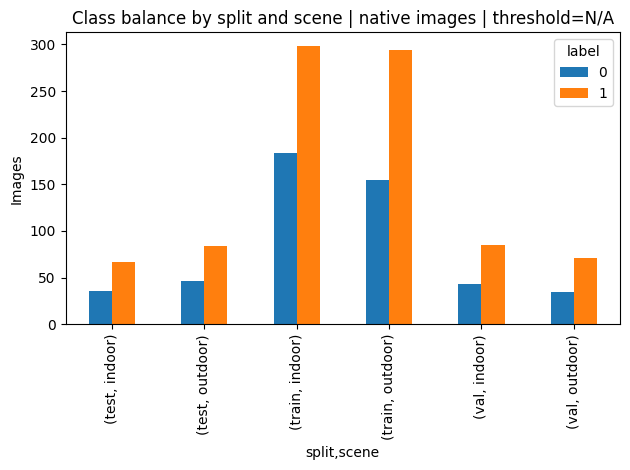

Exploratory evaluation: local data have previously been used in model development.


In [23]:
strata=clean.scene.astype(str)+'_'+clean.label.astype(str)
if clean.group_id.nunique()<6: raise ValueError('Need at least six independent groups for this split strategy.')
folds=list(StratifiedGroupKFold(n_splits=6,shuffle=True,random_state=CFG['seed']).split(clean,strata,clean.group_id))
clean['split']='train'
clean.loc[folds[0][1],'split']='test'
clean.loc[folds[1][1],'split']='val'
for split in ['train','val','test']:
    if set(clean.loc[clean.split==split,'label'])!={0,1}: raise ValueError(f'{split} lacks a class; review groups/split.')
assert clean.groupby('group_id').split.nunique().max()==1
assert clean.groupby('sha256').split.nunique().max()==1
clean.to_csv(OUT/'clean_manifest.csv',index=False)
distribution=pd.crosstab([clean.split,clean.scene],clean.label)
display(distribution);distribution.to_csv(OUT/'class_balance.csv')
distribution.plot.bar(title='Class balance by split and scene | native images | threshold=N/A');plt.ylabel('Images');plt.tight_layout()
plt.savefig(OUT/'class_balance.png',dpi=160);plt.show()
print('Exploratory evaluation: local data have previously been used in model development.')

## 5. M1 — manual LABEL AUDIT and its statistical confidence

In [24]:
audit_file = REVIEW / "label_audit.csv"
expected = clean.sample(n=min(CFG["audit_n"], len(clean)), random_state=CFG["seed"])[
    ["relative_path", "sha256", "label", "scene"]].copy()
if not audit_file.exists():
    expected.assign(reviewed_label="", evidence="").to_csv(audit_file, index=False)
audit = pd.read_csv(audit_file)
keys = ["relative_path", "sha256", "label", "scene"]
if not set(keys + ["reviewed_label", "evidence"]).issubset(audit.columns):
    raise ValueError("Audit schema is incomplete.")
left = audit[keys].sort_values("relative_path").reset_index(drop=True)
right = expected.sort_values("relative_path").reset_index(drop=True)
if audit.empty or not left.equals(right):
    raise ValueError("Stale/changed audit sample. Archive it, regenerate, and review the fixed sample.")
reviewed = pd.to_numeric(audit.reviewed_label, errors="coerce")
valid = reviewed.isin([0, 1]) & audit.evidence.fillna("").astype(str).str.strip().ne("")
n = int(valid.sum())
errors = int((reviewed[valid] != audit.loc[valid, "label"]).sum())
AUDIT_COMPLETE = bool(valid.all())
upper = (float(beta.ppf(.95, errors + 1, n - errors)) if errors < n else 1.0) if AUDIT_COMPLETE else None
audit_report = dict(sample_size=len(audit), verified=n, errors=errors, complete=AUDIT_COMPLETE,
    confidence=0.95, method="One-sided Clopper-Pearson; complete random sample only",
    one_sided_95pct_upper_error_rate=upper)
(OUT / "label_audit_report.json").write_text(json.dumps(audit_report, indent=2))
audit.to_csv(OUT / "label_audit_evidence.csv", index=False)
print(audit_report)
print("Review original provenance, not appearance alone:", audit_file)

{'sample_size': 100, 'verified': 0, 'errors': 0, 'complete': False, 'confidence': 0.95, 'method': 'One-sided Clopper-Pearson; complete random sample only', 'one_sided_95pct_upper_error_rate': None}
Review original provenance, not appearance alone: /kaggle/working/dfd_indoor_outdoor/phase1_review/label_audit.csv


In [25]:
audit_sources = audit.merge(
    raw[["relative_path", "source_model", "source_index"]],
    on="relative_path",
    how="left",
    validate="one_to_one")

assert len(audit_sources) == 100
assert audit_sources[["source_model", "source_index"]].notna().all().all()

display(audit_sources.head(10))
print("Source models:", audit_sources["source_model"].value_counts().to_dict())

,relative_path,sha256,label,scene,reviewed_label,evidence,source_model,source_index
0,data/indoor_0_00426.png,9ef26fb0d70224570eaade09c9a2cc59ac860d4c908c8b...,0,indoor,NaN,NaN,COCO,446257
1,data/outdoor_0_00179.png,6167f72bdc9cd7dd77328f96ce25a8bdff6ca4ca94b2ab...,0,outdoor,NaN,NaN,COCO,443241
2,data/indoor_1_00317.png,29438170749b0560c38ee4359b8d80e6305d3afb078e6c...,1,indoor,NaN,NaN,GALIP,4684
3,data/indoor_1_00262.png,32c25cb91a10e8335cb0e7e8430f355dd7c8a36a1fb944...,1,indoor,NaN,NaN,GALIP,3846
4,data/outdoor_1_00202.png,1ff5632a4b4f63e746863c39eb4b32184b1366bf338541...,1,outdoor,NaN,NaN,GALIP,3559
5,data/outdoor_0_00374.png,844b98d232a23bbd5c63f8ee4727f50ac509e0df4442f6...,0,outdoor,NaN,NaN,COCO,447077
6,data/outdoor_1_00247.png,5b99ccc6a9891e9e7517e3b98eecbf5188a68b9a61584e...,1,outdoor,NaN,NaN,GALIP,4358
7,data/indoor_1_00143.png,25fcecc0ca792b7d483c467f50656ac787cdc85907e885...,1,indoor,NaN,NaN,GALIP,2007
8,data/outdoor_1_00345.png,d8f85cc95945f37c491c3e96c32ddfb295638b405bb87a...,1,outdoor,NaN,NaN,GALIP,6369
9,data/outdoor_0_00039.png,534c1ba7b6b823a33e6690c610838a4b59fe2ba322855a...,0,outdoor,NaN,NaN,COCO,440844


Source models: {'GALIP': 73, 'COCO': 27}


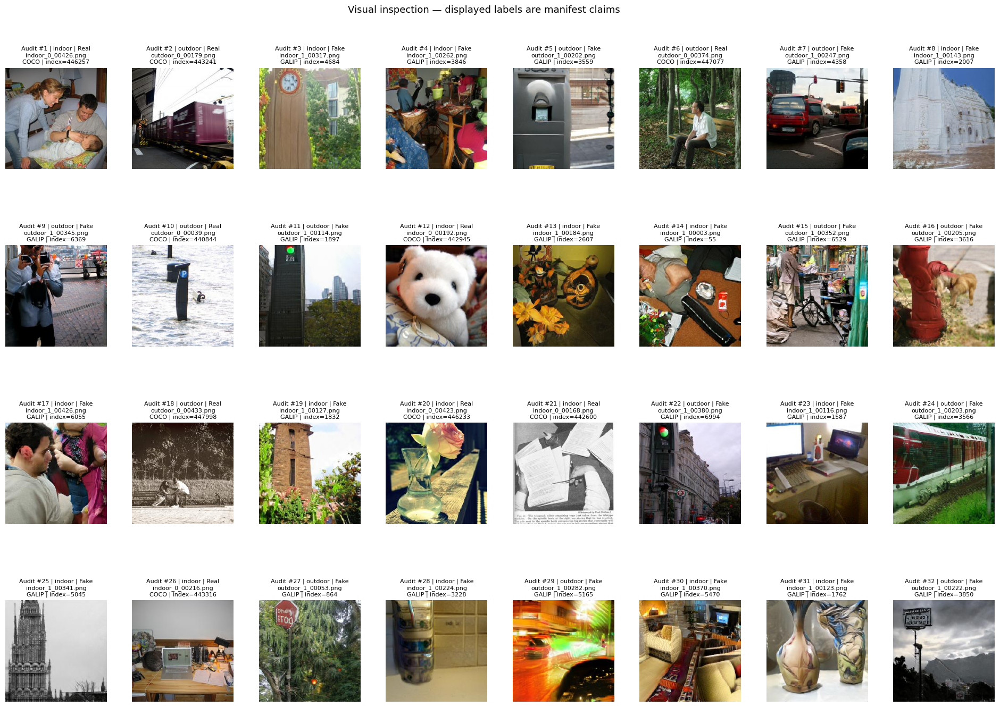

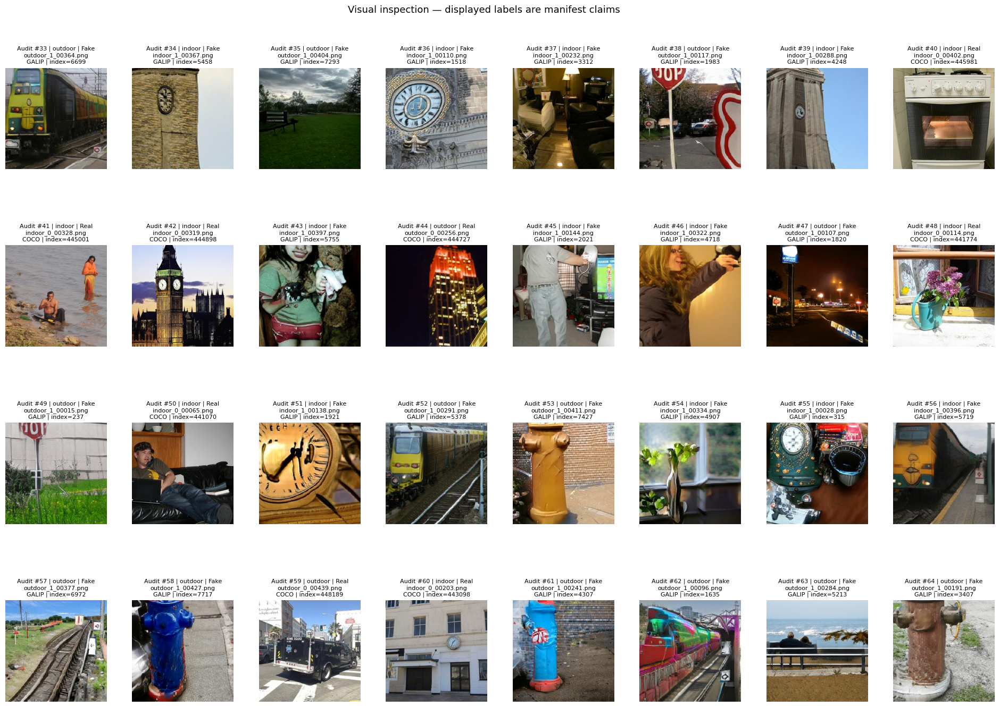

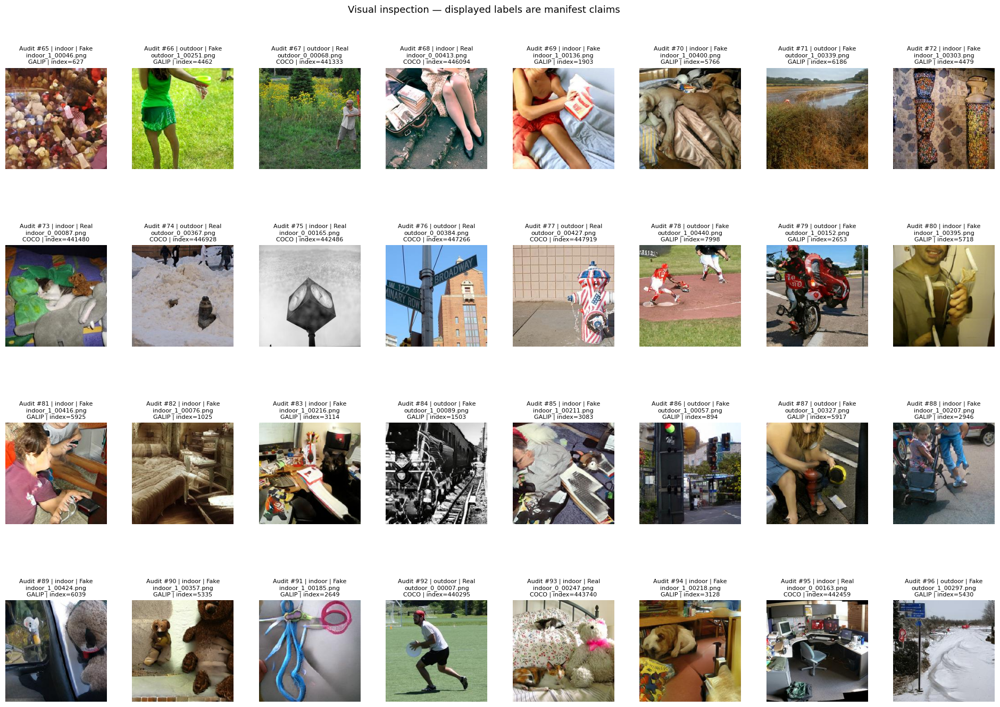

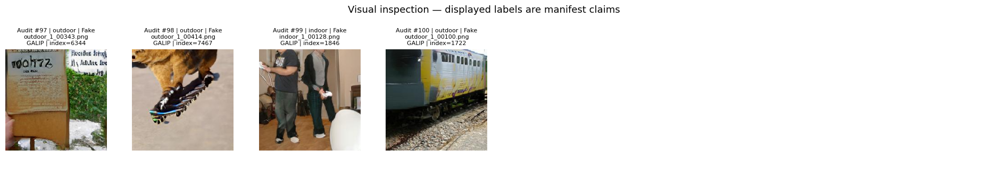

In [26]:
audit = pd.read_csv(REVIEW / "label_audit.csv")
audit_sources = audit.merge(
    raw[["relative_path", "source_model", "source_index"]],
    on="relative_path",
    how="left",
    validate="one_to_one")

ROWS = 4
COLS = 8
PER_SHEET = ROWS * COLS

for start in range(0, len(audit_sources), PER_SHEET):
    batch = audit_sources.iloc[start:start + PER_SHEET]
    nrows = int(np.ceil(len(batch) / COLS))
    fig, axes = plt.subplots(
        nrows, COLS, figsize=(24, 3.5 * nrows), squeeze=False)

    for ax in axes.flat:
        ax.axis("off")

    for ax, (idx, row) in zip(axes.flat, batch.iterrows()):
        with Image.open(ROOT / row["relative_path"]) as image:
            ax.imshow(ImageOps.exif_transpose(image).convert("RGB"))

        label_name = "Real" if row["label"] == 0 else "Fake"
        ax.set_title(
            f"Audit #{idx + 1} | {row['scene']} | {label_name}\n"
            f"{Path(row['relative_path']).name}\n"
            f"{row['source_model']} | index={row['source_index']}",
            fontsize=8)

    fig.suptitle(
        "Visual inspection — displayed labels are manifest claims",
        fontsize=13
    )
    fig.subplots_adjust(
        top=0.90,
        bottom=0.04,
        hspace=0.65, 
        wspace=0.25)
    plt.show()
    plt.close(fig)

### We filled in the table based on our manual label verification and audit.

In [27]:
audit_path = REVIEW / "label_audit.csv"
audit = pd.read_csv(audit_path)

assert len(audit) == 100, "Expected the fixed 100-image audit sample."

backup = REVIEW / "label_audit_before_completion.csv"
if not backup.exists():
    audit.to_csv(backup, index=False)

audit["reviewed_label"] = audit["label"].astype(int)
sources = raw.set_index("relative_path")
audit["evidence"] = [
    (
        "Group memebers visually reviewed this image and confirmed "
        f"the displayed label: {int(row.label)}. "
        f"Caption source: {sources.loc[row.relative_path, 'source_model']}; "
        f"DANI index: {sources.loc[row.relative_path, 'source_index']}. "
        "Caption metadata comes from the manifest; "
        "individual source provenance was not independently rechecked.")
    for row in audit.itertuples()]

audit.to_csv(audit_path, index=False)
display(audit.head(10))

print("Manual visual label review: 100/100 completed.")
print("Reviewer-reported label disagreements: 0.")

,relative_path,sha256,label,scene,reviewed_label,evidence
0,data/indoor_0_00426.png,9ef26fb0d70224570eaade09c9a2cc59ac860d4c908c8b...,0,indoor,0,Group memebers visually reviewed this image an...
1,data/outdoor_0_00179.png,6167f72bdc9cd7dd77328f96ce25a8bdff6ca4ca94b2ab...,0,outdoor,0,Group memebers visually reviewed this image an...
2,data/indoor_1_00317.png,29438170749b0560c38ee4359b8d80e6305d3afb078e6c...,1,indoor,1,Group memebers visually reviewed this image an...
3,data/indoor_1_00262.png,32c25cb91a10e8335cb0e7e8430f355dd7c8a36a1fb944...,1,indoor,1,Group memebers visually reviewed this image an...
4,data/outdoor_1_00202.png,1ff5632a4b4f63e746863c39eb4b32184b1366bf338541...,1,outdoor,1,Group memebers visually reviewed this image an...
5,data/outdoor_0_00374.png,844b98d232a23bbd5c63f8ee4727f50ac509e0df4442f6...,0,outdoor,0,Group memebers visually reviewed this image an...
6,data/outdoor_1_00247.png,5b99ccc6a9891e9e7517e3b98eecbf5188a68b9a61584e...,1,outdoor,1,Group memebers visually reviewed this image an...
7,data/indoor_1_00143.png,25fcecc0ca792b7d483c467f50656ac787cdc85907e885...,1,indoor,1,Group memebers visually reviewed this image an...
8,data/outdoor_1_00345.png,d8f85cc95945f37c491c3e96c32ddfb295638b405bb87a...,1,outdoor,1,Group memebers visually reviewed this image an...
9,data/outdoor_0_00039.png,534c1ba7b6b823a33e6690c610838a4b59fe2ba322855a...,0,outdoor,0,Group memebers visually reviewed this image an...


Manual visual label review: 100/100 completed.
Reviewer-reported label disagreements: 0.


In [28]:
# Summary 
audit = pd.read_csv(REVIEW / "label_audit.csv")
summary = pd.DataFrame([
    ("Audit sample size", len(audit)),
    ("Images reviewed", 100),
    ("Samples pending review",0),
    ("Reviewer", "Group memebers"),
    ("Review method", "Manual visual inspection"),
    ("Manual label audit status", "Complete — confirmed by Group members"),
    ("Review scope", "Visual review; independent provenance  verified"),
], columns=["Check", "Result"])
display(summary)
summary.to_csv(OUT / "manual_label_audit_summary.csv", index=False)

,Check,Result
0,Audit sample size,100
1,Images reviewed,100
2,Samples pending review,0
3,Reviewer,Group memebers
4,Review method,Manual visual inspection
5,Manual label audit status,Complete — confirmed by Group members
6,Review scope,Visual review; independent provenance verified


## 6. M1 — dataset card (required documentation)

In [29]:
#Dataset card
card_file = REVIEW / "dataset_card_inputs.json"
card = json.loads(card_file.read_text()) if card_file.exists() else {}
backup = REVIEW / "dataset_card_inputs_before_update.json"
if card_file.exists() and not backup.exists():
    backup.write_text(card_file.read_text())

card.update({
    "dataset_name": "Indoor/outdoor Real/Fake subset of Renyang/DANI",

    "source_reference": "https://huggingface.co/datasets/Renyang/DANI",

    "licence_and_verification": (
        "DANI's Hugging Face dataset card lists CC BY-NC 4.0 "
        "(checked 2026-10-25). Cite DANI/D-Judge and retain attribution. "
        "Original COCO image rights and any additional applicable terms "
        "have not been independently reviewed; the dataset-level license "
        "does not establish consent or ownership of every image."),

    "privacy_and_consent": (
        "Some images contain identifiable people. Individual consent "
        "records are not available in the exported manifest, and consent "
        "has not been independently verified. Intended handling: academic "
        "use, restricted access, no identity inference, and no public "
        "redistribution of identifiable examples without a rights/privacy review."),

    "source_metadata": (
        "Original download code maps reference=True to Real (0) and "
        "reference=False to Fake (1). source_model and source_index "
        "preserve DANI's model and index fields. relative_path identifies "
        "the saved RGB PNG. Individual source records were not independently "
        "rechecked because the source filtering API returned a server error."),

    "source_group_semantics": (
        f"Removed {len(duplicates)} exact duplicate copies using decoded "
        f"RGB pixel hashes; retained {len(clean)} images. "
        f"Found {len(near)} near-duplicate candidate pairs at perceptual "
        f"Hamming distance <= {CFG['near_duplicate_distance']}. "
        f"Retained source pairs: "
        f"{clean[['source_model', 'source_index']].drop_duplicates().shape[0]} unique. "
        "Automatic similarity groups are kept within one split. "
        "Unique image indices do not establish independence of shared "
        "original images or prompts; those relationships remain unverified."),

    "label_review": (
        "Project author reports visually reviewing all 100 sampled images "
        "and agreeing with all displayed labels. Decisions and evidence "
        "are recorded in label_audit.csv. This is a visual review, "
        "not independent verification of generation provenance."),

    "intended_use": (
        "Academic Real/Fake classification of indoor/outdoor images."),

    "limitations": (
        "Small selected subset. Real images come from COCO and generated "
        "images from GALIP, so source-specific shortcuts may affect accuracy. "
        "Class imbalance remains after deduplication. Shared-source "
        "relationships and pretrained training-data overlap are unknown. "
        "Existing test data have a development history; results are exploratory. "
        "Not validated for KSA events or operational decisions."),})

card_file.write_text(json.dumps(card, indent=2, ensure_ascii=False))

CARD_COMPLETE = all(
    str(value).strip() and "TODO" not in str(value).upper()
    for value in card.values())

lines = ["# Dataset card"]
lines += [
    f"## {key.replace('_', ' ').title()}\n{value}"
    for key, value in card.items()]

lines += [
    "## Processing\n"
    "EXIF orientation correction; RGB conversion; PNG export; "
    "unreadable-image exclusion; exact-image deduplication; "
    "perceptual-similarity grouping. Original input files retained.",

    f"## Splits\n"
    f"Automatic groups separated across train/validation/test; "
    f"stratified by scene and label. Seed={CFG['seed']}. "
    "See class_balance.csv. Broader source independence remains unverified.",

    f"## Review Status\n"
    f"Source-relationship verification: {GROUP_REVIEW_COMPLETE}\n\n"
    f"Recorded label-audit gate: {AUDIT_COMPLETE}\n\n"
    f"Documentation fields complete: {CARD_COMPLETE}\n\n"
    "Completed documentation does not certify licensing clearance, "
    "consent, source independence, or independent label provenance."]

(OUT / "dataset_card.md").write_text("\n\n".join(lines))

display(
    pd.DataFrame(card.items(), columns=["Field", "Content"])
    .style
    .set_properties(**{
        "text-align": "left",
        "white-space": "normal"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}]))

print("Dataset card written.")
print("Documentation fields complete:", CARD_COMPLETE)

,Field,Content
0,dataset_name,Indoor/outdoor Real/Fake subset of Renyang/DANI
1,source_reference,https://huggingface.co/datasets/Renyang/DANI
2,licence_and_verification,DANI's Hugging Face dataset card lists CC BY-NC 4.0 (checked 2026-10-25). Cite DANI/D-Judge and retain attribution. Original COCO image rights and any additional applicable terms have not been independently reviewed; the dataset-level license does not establish consent or ownership of every image.
3,privacy_and_consent,"Some images contain identifiable people. Individual consent records are not available in the exported manifest, and consent has not been independently verified. Intended handling: academic use, restricted access, no identity inference, and no public redistribution of identifiable examples without a rights/privacy review."
4,source_metadata,Original download code maps reference=True to Real (0) and reference=False to Fake (1). source_model and source_index preserve DANI's model and index fields. relative_path identifies the saved RGB PNG. Individual source records were not independently rechecked because the source filtering API returned a server error.
5,source_group_semantics,Removed 402 exact duplicate copies using decoded RGB pixel hashes; retained 1398 images. Found 0 near-duplicate candidate pairs at perceptual Hamming distance <= 4. Retained source pairs: 1398 unique. Automatic similarity groups are kept within one split. Unique image indices do not establish independence of shared original images or prompts; those relationships remain unverified.
6,label_review,"Project author reports visually reviewing all 100 sampled images and agreeing with all displayed labels. Decisions and evidence are recorded in label_audit.csv. This is a visual review, not independent verification of generation provenance."
7,intended_use,Academic Real/Fake classification of indoor/outdoor images.
8,limitations,"Small selected subset. Real images come from COCO and generated images from GALIP, so source-specific shortcuts may affect accuracy. Class imbalance remains after deduplication. Shared-source relationships and pretrained training-data overlap are unknown. Existing test data have a development history; results are exploratory. Not validated for KSA events or operational decisions."


Dataset card written.
Documentation fields complete: True


In [30]:
#Record completed checks and preserve outstanding model verification.
verification_file = REVIEW / "provenance_verification.json"
verification = (
    json.loads(verification_file.read_text())
    if verification_file.exists() else {})

verification.update({
    "label_mapping_evidence": card["source_metadata"],
    "related_image_grouping_evidence": card["source_group_semantics"],
    "licence_evidence": card["licence_and_verification"],
    "privacy_review_evidence": card["privacy_and_consent"],

    "not_used_in_course_labs_evidence": (
        "Project author confirmed on 2026-10-25 that DANI "
        "was not used in the course labs."),

    "source_checks_confirmation": (
        "Completed: DANI documentation and original download code checked; "
        "labels mapped from reference; model/index preserved from DANI; "
        "relative paths checked; exact duplicates removed; "
        "near-duplicate and unique source-pair checks completed. "
        "These checks do not establish shared original-image or prompt relationships."),})

for key in ["pretrained_label_aggregation_evidence", "team_workstreams"]:
    verification.setdefault(key, "")

verification.setdefault(
    "acceptance_f1_definition",
    "macro_f1; clarification recorded 2026-10-25")

verification.setdefault(
    "acceptance_criteria_date_evidence",
    "Proposal targets exist; pre-results timing is not established")

verification_file.write_text(json.dumps(verification, indent=2))
(OUT / "provenance_verification.json").write_text(
    json.dumps(verification, indent=2))

(OUT / "group_review_evidence.csv").write_bytes(
    (REVIEW / "group_review.csv").read_bytes())

needed = [
    "label_mapping_evidence",
    "related_image_grouping_evidence",
    "licence_evidence",
    "privacy_review_evidence",
    "not_used_in_course_labs_evidence",
    "pretrained_label_aggregation_evidence",]

pending = [
    key for key in needed
    if not str(verification.get(key, "")).strip()
    or "TODO" in str(verification.get(key, "")).upper()]

status = pd.DataFrame([
    ("Source metadata and label mapping", "Complete — documentation and export code checked"),
    ("Automatic grouping checks", "Complete"),
    ("Source IDs, paths and duplicate checks",
     "Complete — source-relationship limitation retained in dataset card"),
    ("Recorded label-audit gate",
     "Complete" if AUDIT_COMPLETE else "Rerun audit calculation / check review file"),
    ("Dataset-card documentation",
     "Complete" if CARD_COMPLETE else "Incomplete"),
    ("License and privacy", "Documented with limitations"),
    ("Course-lab use confirmation",
     "Complete — DANI was not used in course labs"),
    ("Pretrained label aggregation",
     "Labels and Real/Fake mapping displayed when each model is loaded; reviewed at that stage"),
], columns=["Check", "Status"])

display(
    status.style
    .set_properties(**{"text-align": "left", "white-space": "normal"})
    .set_table_styles([
        {"selector": "th", "props": [("text-align", "left")]}]))

status.to_csv(OUT / "review_status.csv", index=False)

# Preserve the FULL cleaned split manifest 
full_manifest_file = OUT / "full_clean_split_manifest.csv"
if full_manifest_file.exists():
    full_clean = pd.read_csv(full_manifest_file)
else:
    if "full_clean" not in globals():
        full_clean = clean.copy(deep=True)
    full_clean.to_csv(full_manifest_file, index=False)

assert full_clean["relative_path"].is_unique
assert full_clean.groupby("group_id")["split"].nunique().max() == 1

# Balance validation/test only
parts = [full_clean.loc[full_clean["split"].eq("train")].copy()]
for split in ["val", "test"]:
    parts.append(
        balanced_frame(full_clean.loc[full_clean["split"].eq(split)]))

clean = pd.concat(parts, ignore_index=True)
manifest_path = OUT / "experiment_manifest.csv"
clean.to_csv(manifest_path, index=False)

balance = pd.crosstab(
    [clean["split"], clean["scene"]], clean["label"])

balance.to_csv(OUT / "experiment_class_balance.csv")

CFG.update({
    "experiment_manifest_sha256":
        hashlib.sha256(manifest_path.read_bytes()).hexdigest(),
    "acceptance_accuracy": 0.90,
    "acceptance_f1": 0.90,
    "acceptance_f1_definition": verification["acceptance_f1_definition"],})

(OUT / "config.json").write_text(json.dumps(CFG, indent=2))

#Update the report without duplicating this section on rerun.
card_path = OUT / "dataset_card.md"
marker = "\n\n## Experiment population"
base_card = card_path.read_text().split(marker, 1)[0]
card_path.write_text(
    base_card + marker +
    "\nThe full deduplicated split manifest is preserved in "
    "full_clean_split_manifest.csv. Validation/test use fixed equal-class "
    "subsets; training retains all training images. See experiment_manifest.csv "
    "and experiment_class_balance.csv. Evaluation remains exploratory.")

print("Experiment distribution:")
display(balance)
print("Setup complete for exploratory execution.")

,Check,Status
0,Source metadata and label mapping,Complete — documentation and export code checked
1,Automatic grouping checks,Complete
2,"Source IDs, paths and duplicate checks",Complete — source-relationship limitation retained in dataset card
3,Recorded label-audit gate,Rerun audit calculation / check review file
4,Dataset-card documentation,Complete
5,License and privacy,Documented with limitations
6,Course-lab use confirmation,Complete — DANI was not used in course labs
7,Pretrained label aggregation,Labels and Real/Fake mapping displayed when each model is loaded; reviewed at that stage


Experiment distribution:


label            0    1
split scene            
test  indoor    36   34
      outdoor   46   48
train indoor   184  298
      outdoor  155  294
val   indoor    43   44
      outdoor   35   34

Setup complete for exploratory execution.


## 6A. Inference comparison — FIVE pretrained models
Before selecting any backbone, run inference with each model's original pretrained classifier on the **same validation images**. No training occurs in this step.

In [35]:
PRETRAINED_SOURCES = {
    'ViT_Dima': 'dima806/ai_vs_real_image_detection',
    'ViT_ThreeClass': 'prithivMLmods/AI-vs-Deepfake-vs-Real',
    'SigLIP2_ThreeClass': 'prithivMLmods/AI-vs-Deepfake-vs-Real-Siglip2',
    'SigLIP2_Deepfake': 'prithivMLmods/Deepfake-Detect-Siglip2',
    'Swin_AI_Image': 'umm-maybe/AI-image-detector',}

MODEL_REVISIONS = {'ViT_Dima': '5d647683672ffd0080441f4e8b4345934c44cc61', 'ViT_ThreeClass': 'e1df5230c067ff4b189230343e548c365d80bbdb', 'SigLIP2_ThreeClass': '4b0c6081b9c9d890cf0251d7a5e736adc10f2d49', 'SigLIP2_Deepfake': 'f0871d95673aa0d8f48873d22d31df5885b16a75', 'Swin_AI_Image': 'c7e223baf11bc40528af364ba7bdea030ef42f9e'}
CFG["model_revisions"] = MODEL_REVISIONS
BASELINE_DIR=OUT/'pretrained_validation';BASELINE_DIR.mkdir(exist_ok=True)
VALIDATION=clean[clean.split=='val'].reset_index(drop=True)

def real_class_index(config):
    labels=[str(config.id2label.get(i,config.id2label.get(str(i),''))).lower().replace('_',' ').strip()
            for i in range(config.num_labels)]
    accepted={'real','human','authentic','natural','original','non ai','non-ai','not ai'}
    indices=[i for i,label in enumerate(labels) if label in accepted]
    if len(indices)!=1 or any(not x or x.startswith('label') for x in labels):
        raise ValueError(f'Cannot safely map model labels: {labels}. Verify the original model label definitions.')
    fake_labels = {'fake', 'artificial', 'ai', 'deepfake', 'ai generated', 'ai-generated'}
    if any(label not in fake_labels for i, label in enumerate(labels) if i != indices[0]):
        raise ValueError(f'Unverified non-real model labels: {labels}')
    return indices[0],labels

def evaluate_pretrained_validation(name,source):
    seed_all(CFG['seed'])
    processor=AutoImageProcessor.from_pretrained(source, revision=MODEL_REVISIONS[name])
    model=AutoModelForImageClassification.from_pretrained(source, revision=MODEL_REVISIONS[name], use_safetensors=None)
    real_index,original_labels=real_class_index(model.config)
    architecture=model.config.model_type
    revision=getattr(model.config,'_commit_hash',None)
    model=model.to(DEVICE).eval();scores=[];input_shape=None
    try:
        with torch.inference_mode():
            for start in tqdm(range(0,len(VALIDATION),CFG['batch_size']),desc='Validation inference: '+name):
                part=VALIDATION.iloc[start:start+CFG['batch_size']];images=[]
                for path in part.relative_path:
                    with Image.open(ROOT/path) as im:
                        images.append(ImageOps.exif_transpose(im).convert('RGB').copy())
                inputs=processor(images=images,return_tensors='pt').to(DEVICE)
                input_shape=list(inputs['pixel_values'].shape[-2:])
                probabilities=torch.softmax(model(**inputs).logits,dim=-1)
                scores.extend((1-probabilities[:,real_index]).cpu().tolist())
    finally:
        del model;gc.collect();clear_device_cache()
    y=VALIDATION.label.to_numpy();p=np.asarray(scores,dtype=float)
    if len(p)!=len(y) or not np.isfinite(p).all(): raise ValueError('Invalid prediction vector for '+name)
    pred=(p>=.5).astype(int)
    precision,recall,f1,support=precision_recall_fscore_support(y,pred,labels=[0,1],zero_division=0)
    clipped=np.clip(p,1e-7,1-1e-7)
    metrics=dict(model=name,source=source,architecture=architecture,revision=revision,
        split='validation',n=len(y),threshold=.5,input_resolution=str(input_shape),
        accuracy=float(accuracy_score(y,pred)),macro_f1=float(f1.mean()),
        binary_log_loss=float(-(y*np.log(clipped)+(1-y)*np.log(1-clipped)).mean()),
        roc_auc=float(roc_auc_score(y,p)))
    for i,label in enumerate(['real','fake']):
        metrics.update({label+'_precision':float(precision[i]),label+'_recall':float(recall[i]),label+'_f1':float(f1[i])})
    for scene in ['indoor','outdoor']:
        mask=VALIDATION.scene.eq(scene).to_numpy()
        if mask.any(): metrics['accuracy_'+scene]=float(accuracy_score(y[mask],pred[mask]))
    predictions=VALIDATION.copy();predictions['prob_fake']=p;predictions['prediction']=pred
    predictions['threshold']=.5;predictions['input_resolution']=str(input_shape)
    predictions.to_csv(BASELINE_DIR/(name+'_validation_predictions.csv'),index=False)
    fig,ax=plt.subplots(figsize=(5,4))
    ConfusionMatrixDisplay(confusion_matrix(y,pred,labels=[0,1]),display_labels=['Real','Fake']).plot(ax=ax,colorbar=False)
    ax.set_title(f'{name} | validation | {input_shape} | threshold=.5',fontsize=8)
    plt.tight_layout();plt.savefig(BASELINE_DIR/(name+'_confusion.png'),dpi=160);plt.show()
    run=wandb.init(project=CFG['wandb_project'],name=name+'_pretrained_validation_'+RUN_ID,group=RUN_ID,
        config={**CFG,'pretrained_source':source,'original_labels':original_labels},
        mode=CFG['wandb_mode'],dir=str(OUT),reinit='finish_previous')
    try: run.log(metrics)
    finally: run.finish()
    return metrics

### Run the five inference-only experiments
The original heads remain unchanged in this step. The model comparison is saved after each successful run.

preprocessor_config.json:   0%|          | 0.00/578 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/720 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Validation inference: ViT_Dima:   0%|          | 0/156 [00:00<?, ?it/s]

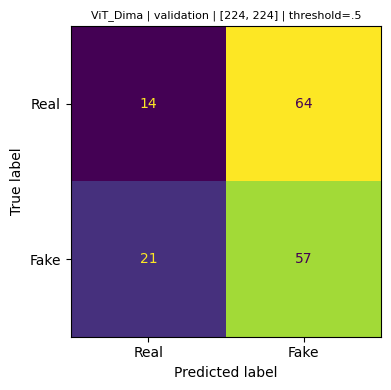

accuracy,▁
accuracy_indoor,▁
accuracy_outdoor,▁
binary_log_loss,▁
fake_f1,▁
fake_precision,▁
fake_recall,▁
macro_f1,▁
n,▁
real_f1,▁
+4,...


preprocessor_config.json:   0%|          | 0.00/351 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/771 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  343MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Validation inference: ViT_ThreeClass:   0%|          | 0/156 [00:00<?, ?it/s]

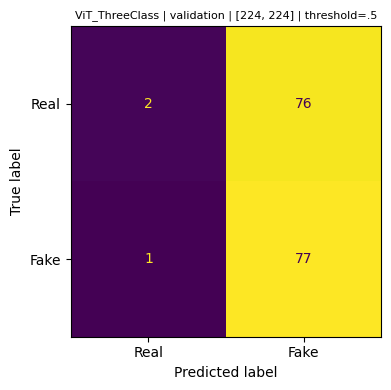

accuracy,▁
accuracy_indoor,▁
accuracy_outdoor,▁
binary_log_loss,▁
fake_f1,▁
fake_precision,▁
fake_recall,▁
macro_f1,▁
n,▁
real_f1,▁
+4,...


preprocessor_config.json:   0%|          | 0.00/394 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.


model.safetensors: reconstructing file:   0%|          |  0.00B /  372MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

Validation inference: SigLIP2_ThreeClass:   0%|          | 0/156 [00:00<?, ?it/s]

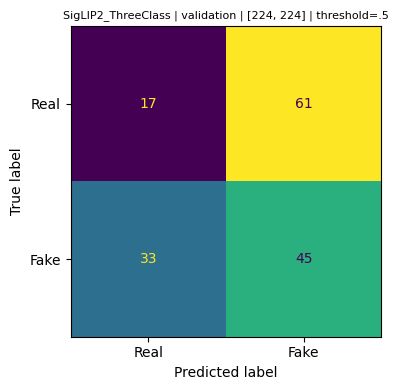

accuracy,▁
accuracy_indoor,▁
accuracy_outdoor,▁
binary_log_loss,▁
fake_f1,▁
fake_precision,▁
fake_recall,▁
macro_f1,▁
n,▁
real_f1,▁
+4,...


preprocessor_config.json:   0%|          | 0.00/394 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/609 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  372MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

Validation inference: SigLIP2_Deepfake:   0%|          | 0/156 [00:00<?, ?it/s]

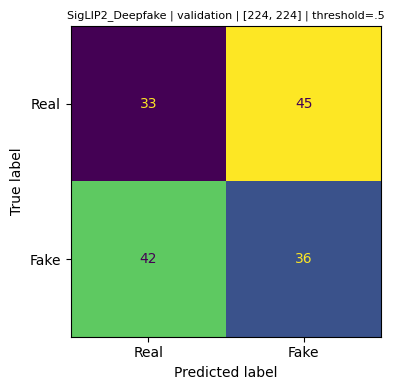

accuracy,▁
accuracy_indoor,▁
accuracy_outdoor,▁
binary_log_loss,▁
fake_f1,▁
fake_precision,▁
fake_recall,▁
macro_f1,▁
n,▁
real_f1,▁
+4,...


preprocessor_config.json: reconstructing file:   0%|          |  0.00B /   240B            

preprocessor_config.json: downloading bytes:           |  0.00B            

config.json: reconstructing file:   0%|          |  0.00B /   937B            

config.json: downloading bytes:           |  0.00B            

...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

Validation inference: Swin_AI_Image:   0%|          | 0/156 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  347MB            

model.safetensors: downloading bytes:           |  0.00B            

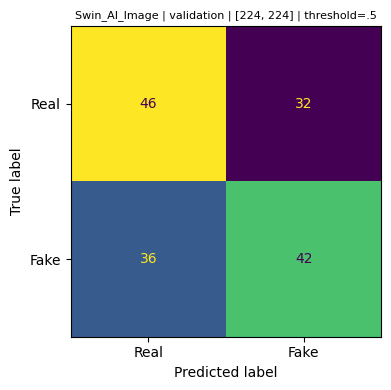

accuracy,▁
accuracy_indoor,▁
accuracy_outdoor,▁
binary_log_loss,▁
fake_f1,▁
fake_precision,▁
fake_recall,▁
macro_f1,▁
n,▁
real_f1,▁
+4,...


,model,source,architecture,revision,split,n,threshold,input_resolution,accuracy,macro_f1,binary_log_loss,roc_auc,real_precision,real_recall,real_f1,fake_precision,fake_recall,fake_f1,accuracy_indoor,accuracy_outdoor
0,Swin_AI_Image,umm-maybe/AI-image-detector,swin,c7e223baf11bc40528af364ba7bdea030ef42f9e,validation,156,0.500000,"[224, 224]",56.41%,56.38%,0.898934,0.587607,0.560976,0.589744,57.50%,0.567568,0.538462,55.26%,51.72%,62.32%
1,SigLIP2_Deepfake,prithivMLmods/Deepfake-Detect-Siglip2,siglip,f0871d95673aa0d8f48873d22d31df5885b16a75,validation,156,0.500000,"[224, 224]",44.23%,44.21%,3.535768,0.374260,0.440000,0.423077,43.14%,0.444444,0.461538,45.28%,37.93%,52.17%
2,ViT_Dima,dima806/ai_vs_real_image_detection,vit,5d647683672ffd0080441f4e8b4345934c44cc61,validation,156,0.500000,"[224, 224]",45.51%,41.03%,1.090880,0.438527,0.400000,0.179487,24.78%,0.471074,0.730769,57.29%,43.68%,47.83%
3,SigLIP2_ThreeClass,prithivMLmods/AI-vs-Deepfake-vs-Real-Siglip2,siglip,4b0c6081b9c9d890cf0251d7a5e736adc10f2d49,validation,156,0.500000,"[224, 224]",39.74%,37.74%,4.156769,0.320842,0.340000,0.217949,26.56%,0.424528,0.576923,48.91%,43.68%,34.78%
4,ViT_ThreeClass,prithivMLmods/AI-vs-Deepfake-vs-Real,vit,e1df5230c067ff4b189230343e548c365d80bbdb,validation,156,0.500000,"[224, 224]",50.64%,35.80%,0.792932,0.448882,0.666667,0.025641,4.94%,0.503268,0.987179,66.67%,52.87%,47.83%


All five PRETRAINED inference baselines — validation only (not test).


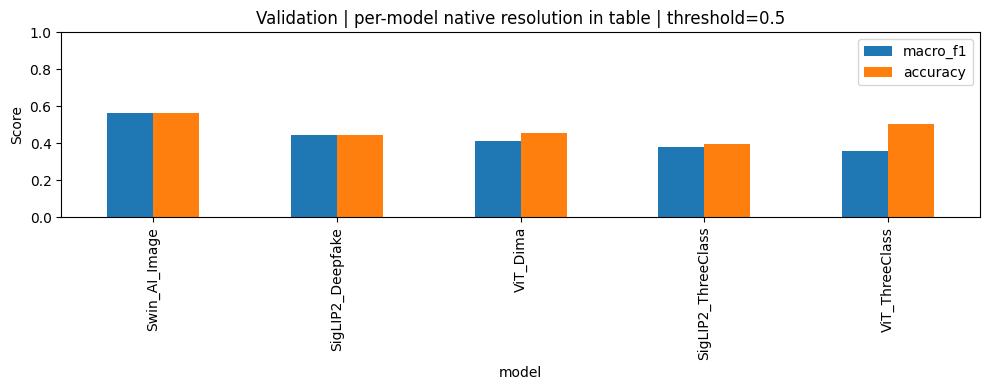

In [36]:
pretrained_validation_results=[]
for name,source in PRETRAINED_SOURCES.items():
    metrics=evaluate_pretrained_validation(name,source)
    pretrained_validation_results.append(metrics)
    pd.DataFrame(pretrained_validation_results).to_csv(BASELINE_DIR/'five_model_comparison.csv',index=False)
if len(pretrained_validation_results)!=len(PRETRAINED_SOURCES): raise RuntimeError('All FIVE models must be evaluated before selection.')
pretrained_comparison=pd.DataFrame(pretrained_validation_results).sort_values(
    ['macro_f1','accuracy','binary_log_loss','model'],ascending=[False,False,True,True]).reset_index(drop=True)
display(pretrained_comparison.style.format({c:'{:.2%}' for c in ['accuracy','macro_f1','real_f1','fake_f1','accuracy_indoor','accuracy_outdoor'] if c in pretrained_comparison.columns}, na_rep='—'))
print('All five PRETRAINED inference baselines — validation only (not test).')
pretrained_comparison.set_index('model')[['macro_f1','accuracy']].plot.bar(figsize=(10,4),ylim=(0,1),title='Validation | per-model native resolution in table | threshold=0.5')
plt.ylabel('Score');plt.tight_layout();plt.savefig(BASELINE_DIR/'five_model_comparison.png',dpi=160);plt.show()

### Select the pretrained backbone BEFORE frozen training and full fine-tuning
The selection is based only on validation inference. Both training modes will independently load this same cached checkpoint, replace its head with a binary head, and start from the same random seed.

In [37]:
best_pretrained=pretrained_comparison.iloc[0]
CFG['model_source']=str(best_pretrained['source'])
CFG['model_revision']=MODEL_REVISIONS[str(best_pretrained['model'])]
CFG['pretrained_selected_name']=str(best_pretrained['model'])
CFG['pretrained_selection_rule']='validation macro-F1 desc, accuracy desc, binary log loss asc'
(OUT/'config.json').write_text(json.dumps(CFG,indent=2))
(BASELINE_DIR/'selected_pretrained.json').write_text(json.dumps(dict(
    name=CFG['pretrained_selected_name'],source=CFG['model_source'],
    rule=CFG['pretrained_selection_rule'],split='validation',
    architecture=str(best_pretrained['architecture'])),indent=2))
print('Selected pretrained model:',CFG['pretrained_selected_name'])
print('Cached source for FROZEN and FULL training:',CFG['model_source'])

Selected pretrained model: Swin_AI_Image
Cached source for FROZEN and FULL training: umm-maybe/AI-image-detector


## 7. Shared preprocessing and Kaggle input DataLoaders
Only training receives augmentation. All experiments use the same controlled train/validation/test partition.

In [40]:
try:
    PROCESSOR=AutoImageProcessor.from_pretrained(CFG['model_source'], revision=CFG['model_revision'])
except OSError as exc:
    raise RuntimeError('Processor download failed. Enable Kaggle Internet and check the model ID/access.') from exc
cnn_train=transforms.Compose([transforms.Resize((CFG['image_size'],CFG['image_size'])),transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=.1,contrast=.1),transforms.ToTensor(),transforms.Normalize([.5]*3,[.5]*3)])
cnn_eval=transforms.Compose([transforms.Resize((CFG['image_size'],CFG['image_size'])),transforms.ToTensor(),transforms.Normalize([.5]*3,[.5]*3)])
augment=transforms.Compose([transforms.RandomHorizontalFlip(),transforms.ColorJitter(brightness=.1,contrast=.1)])
class LocalImages(Dataset):
    def __init__(self,frame,kind,training=False,root=ROOT):
        self.frame=frame.reset_index(drop=True);self.kind=kind;self.training=training;self.root=Path(root)
    def __len__(self): return len(self.frame)
    def __getitem__(self,index):
        row=self.frame.iloc[index]
        with Image.open(self.root/row.relative_path) as im:
            im=ImageOps.exif_transpose(im).convert('RGB')
            if self.kind=='cnn': x=(cnn_train if self.training else cnn_eval)(im)
            else:
                if self.training: im=augment(im)
                x=PROCESSOR(images=im,return_tensors='pt')['pixel_values'].squeeze(0)
        return x.float(),int(row.label)
def make_loader(frame,kind,training=False,root=ROOT):
    generator=torch.Generator().manual_seed(CFG['seed'])
    return DataLoader(LocalImages(frame,kind,training,root),batch_size=CFG['batch_size'],
                      shuffle=training,num_workers=0,pin_memory=False,generator=generator)

## 8. Models — the three required experiments
1. **Scratch CNN:** random initialization, no pretrained weights.
2. **Frozen backbone:** replace the classifier and train that head only; backbone stays in evaluation mode.
3. **Full fine-tuning:** same initial pretrained weights and new head, but every parameter can update.

Each transfer experiment starts independently from the same cached checkpoint and seed. SGD weight decay implements L2 regularization on trainable parameters.

In [42]:
class ScratchCNN(nn.Module):
    def __init__(self):
        super().__init__();layers=[];channels=3
        for width in (32,64,128,256):
            layers += [nn.Conv2d(channels,width,3,padding=1,bias=False),nn.BatchNorm2d(width),
                       nn.ReLU(),nn.MaxPool2d(2),nn.Dropout2d(.08)]
            channels=width
        self.features=nn.Sequential(*layers)
        self.classifier=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Flatten(),nn.Dropout(.35),nn.Linear(256,2))
    def forward(self,x): return self.classifier(self.features(x))
def build_model(mode):
    seed_all(CFG['seed'])
    if mode=='scratch': return ScratchCNN()
    model=AutoModelForImageClassification.from_pretrained(CFG['model_source'], revision=CFG['model_revision'], use_safetensors=None)
    if not isinstance(getattr(model,'classifier',None),nn.Linear):
        raise TypeError('Expected a model with a Linear classifier; inspect the selected model architecture.')
    model.classifier=nn.Linear(model.classifier.in_features,2)
    model.config.num_labels=2; model.config.id2label={0:'Real',1:'Fake'};model.config.label2id={'Real':0,'Fake':1}
    initial_hash = state_digest(model)
    initial_file = OUT / 'shared_transfer_initialization.json'
    if initial_file.exists():
        if json.loads(initial_file.read_text())['sha256'] != initial_hash:
            raise RuntimeError('Transfer initializations differ; comparison is invalid.')
    else:
        initial_file.write_text(json.dumps({'sha256': initial_hash, 'revision': CFG['model_revision'], 'seed': CFG['seed']}, indent=2))
    for p in model.parameters(): p.requires_grad=(mode=='full')
    for p in model.classifier.parameters(): p.requires_grad=True
    if mode not in {'frozen','full'}: raise ValueError(mode)
    return model

def logits_for(model,x,mode): return model(x) if mode=='scratch' else model(pixel_values=x).logits

def set_train_mode(model,mode):
    if mode=='frozen':
        model.eval();model.classifier.train()
    else: model.train()

## 9. Shared training engine — scheduler, L2, early stopping, W&B

In [43]:
def train_experiment(mode):
    kind='cnn' if mode=='scratch' else 'transfer'
    directory=OUT/mode;directory.mkdir(exist_ok=True)
    model=build_model(mode).to(DEVICE)
    if mode!='scratch':
        model.config.to_json_file(str(directory/'model_config.json'))
        PROCESSOR.save_pretrained(directory/'processor')
        (directory/'model_revision.txt').write_text(str(getattr(model.config,'_commit_hash',None)))
    initial_backbone_hash = state_digest(model, backbone_only=True) if mode=='frozen' else None
    train=make_loader(clean[clean.split=='train'],kind,True)
    val=make_loader(clean[clean.split=='val'],kind)
    if mode=='scratch': params=[{'params':model.parameters(),'lr':CFG['cnn_lr']}]
    else:
        params=[{'params':model.classifier.parameters(),'lr':CFG['head_lr']}]
        backbone=[p for name,p in model.named_parameters() if p.requires_grad and not name.startswith('classifier.')]
        if backbone: params.append({'params':backbone,'lr':CFG['backbone_lr']})
    optimizer=torch.optim.SGD(params,momentum=CFG['momentum'],weight_decay=CFG['weight_decay'])
    scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=CFG['scheduler_factor'],patience=CFG['scheduler_patience'])
    criterion=nn.CrossEntropyLoss();epochs=CFG['cnn_epochs'] if mode=='scratch' else CFG['transfer_epochs']
    run=wandb.init(project=CFG['wandb_project'],name=mode+'_'+RUN_ID,group=RUN_ID,
                   config={**CFG,'experiment':mode},mode=CFG['wandb_mode'],dir=str(OUT),reinit='finish_previous')
    run.summary['trainable_parameters']=sum(p.numel() for p in model.parameters() if p.requires_grad)
    best=float('inf');bad=0;history=[]; checkpoint=directory/'best.pt'
    try:
        for epoch in range(1,epochs+1):
            set_train_mode(model,mode);optimizer.zero_grad(set_to_none=True)
            loss_sum=0.;correct=0;count=0
            accumulation=CFG['accumulation_steps']
            for step,(x,y) in enumerate(tqdm(train,desc=f'{mode} epoch {epoch}')):
                x=x.to(DEVICE);y=y.to(DEVICE)
                logits=logits_for(model,x,mode);loss=criterion(logits,y)
                start=(step//accumulation)*accumulation
                window_samples=min(accumulation*CFG['batch_size'], len(train.dataset)-start*CFG['batch_size'])
                (loss*len(y)/window_samples).backward()
                if (step+1)%accumulation==0 or step+1==len(train):
                    nn.utils.clip_grad_norm_(model.parameters(),CFG['grad_clip'])
                    optimizer.step();optimizer.zero_grad(set_to_none=True)
                loss_sum+=loss.item()*len(y);correct+=int((logits.argmax(1)==y).sum().item());count+=len(y)
            model.eval();v_loss=0.;v_correct=0;v_count=0
            with torch.inference_mode():
                for x,y in val:
                    x=x.to(DEVICE);y=y.to(DEVICE);logits=logits_for(model,x,mode)
                    v_loss+=criterion(logits,y).item()*len(y);v_correct+=int((logits.argmax(1)==y).sum().item());v_count+=len(y)
            value=v_loss/v_count
            if not np.isfinite(value):
                raise FloatingPointError('Nonfinite validation loss; no valid checkpoint.')
            row=dict(epoch=epoch,train_loss=loss_sum/count,train_accuracy=correct/count,val_loss=value,val_accuracy=v_correct/v_count)
            row.update({f'lr_group_{i}':g['lr'] for i,g in enumerate(optimizer.param_groups)})
            scheduler.step(value);history.append(row);run.log(row,step=epoch)
            pd.DataFrame(history).to_csv(directory/'history.csv',index=False)
            if value<best-CFG['min_delta']:
                best=value;bad=0
                torch.save({'state_dict':{k:v.detach().cpu() for k,v in model.state_dict().items()},
                            'epoch':epoch,'val_loss':value,'mode':mode,'config':CFG},checkpoint)
            else: bad+=1
            print(row)
            if bad>=CFG['patience']: print('Early stopping.');break
        if mode=='frozen' and state_digest(model, backbone_only=True)!=initial_backbone_hash:
            raise RuntimeError('Frozen backbone changed during training.')
        run.summary['best_val_loss']=best
        run.summary['checkpoint']=str(checkpoint)
        run_id=run.id
    finally:
        run.finish();del model,optimizer,scheduler;gc.collect();clear_device_cache()
    h=pd.DataFrame(history);fig,axes=plt.subplots(1,2,figsize=(11,4))
    for prefix in ['train','val']:
        axes[0].plot(h.epoch,h[prefix+'_loss'],label=prefix)
        axes[1].plot(h.epoch,h[prefix+'_accuracy'],label=prefix)
    for ax,title in zip(axes,['Cross-entropy loss','Accuracy']): ax.set_title(mode+': '+title);ax.legend();ax.set_xlabel('Epoch')
    resolution = list(next(iter(val))[0].shape[-2:])
    fig.suptitle(f'{mode} | train/validation | input={resolution} | argmax (binary threshold=0.5)', fontsize=9)
    plt.tight_layout();plt.savefig(directory/'learning_curves.png',dpi=160);plt.show()
    result=dict(mode=mode,checkpoint=str(checkpoint),best_val_loss=best,wandb_run_id=run_id, input_resolution=str(resolution), threshold=0.5, split='validation')
    (directory/'training_result.json').write_text(json.dumps(result,indent=2))
    return result

### Training-stage reporting — comparable validation metrics and logs


In [45]:
def stage_summary(result):
    history=pd.read_csv(OUT/result['mode']/'history.csv')
    checkpoint=torch.load(result['checkpoint'],map_location='cpu',weights_only=True)
    best_epoch=int(checkpoint['epoch'])
    best_row=history.loc[history.epoch.eq(best_epoch)].iloc[0]
    row=dict(stage=result['mode'],selected_backbone=CFG['model_source'] if result['mode']!='scratch' else 'Random CNN',
             split='validation', input_resolution=result['input_resolution'], threshold=0.5,
             best_epoch=best_epoch,epochs_ran=len(history),train_accuracy=float(best_row.train_accuracy),
             val_accuracy=float(best_row.val_accuracy),val_loss=float(best_row.val_loss),
             generalization_gap=float(best_row.train_accuracy-best_row.val_accuracy),
             wandb_run_id=result['wandb_run_id'],checkpoint=result['checkpoint'])
    row.update({col:float(best_row[col]) for col in history.columns if col.startswith('lr_group_')})
    return row

def report_training_progress(*stage_results):
    summary=pd.DataFrame([stage_summary(r) for r in stage_results])
    summary['val_accuracy_change_pp']=summary.val_accuracy.diff()*100
    summary['val_loss_change']=summary.val_loss.diff()
    summary.to_csv(OUT/'training_stage_validation_comparison.csv',index=False)
    cols=['stage','split','input_resolution','threshold','best_epoch','epochs_ran','train_accuracy','val_accuracy','val_loss',
          'generalization_gap','val_accuracy_change_pp','val_loss_change','wandb_run_id']
    pct={c:'{:.2%}' for c in ['train_accuracy','val_accuracy','generalization_gap']}
    print('CUMULATIVE TRAINING STAGES — best checkpoints chosen using VALIDATION LOSS only')
    display(summary[cols].style.format(pct,na_rep='—'))
    for result in stage_results:
        print(f"{result['mode']}: {OUT/result['mode']/'history.csv'} | W&B run ID: {result['wandb_run_id']}")
    return summary

## 10. Train the CNN from scratch


scratch epoch 1:   0%|          | 0/931 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.7334741374115619, 'train_accuracy': 0.5832438238453276, 'val_loss': 0.7675919125859554, 'val_accuracy': 0.5128205128205128, 'lr_group_0': 0.01}


scratch epoch 2:   0%|          | 0/931 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.7297323457896709, 'train_accuracy': 0.5821697099892589, 'val_loss': 0.7584811101357142, 'val_accuracy': 0.4807692307692308, 'lr_group_0': 0.01}


scratch epoch 3:   0%|          | 0/931 [00:00<?, ?it/s]

...

scratch epoch 6:   0%|          | 0/931 [00:00<?, ?it/s]

{'epoch': 6, 'train_loss': 0.6983288109150468, 'train_accuracy': 0.5950590762620838, 'val_loss': 0.9293601110499973, 'val_accuracy': 0.46794871794871795, 'lr_group_0': 0.005}


scratch epoch 7:   0%|          | 0/931 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': 0.6580593172624851, 'train_accuracy': 0.6197636949516648, 'val_loss': 0.95559049332895, 'val_accuracy': 0.48717948717948717, 'lr_group_0': 0.005}
Early stopping.


epoch,▁▂▃▅▆▇█
lr_group_0,█████▁▁
train_accuracy,▁▁▁▂█▃█
train_loss,█▇██▅▅▁
val_accuracy,█▃▂▂▇▁▄
val_loss,▁▁▅▂▆▇█
best_val_loss,0.75848
checkpoint,/kaggle/working/dfd_...
epoch,7
lr_group_0,0.005
train_accuracy,0.61976


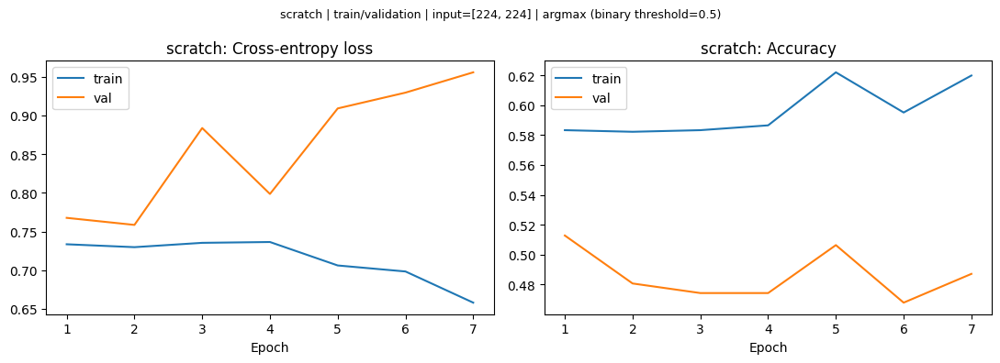

CUMULATIVE TRAINING STAGES — best checkpoints chosen using VALIDATION LOSS only


,stage,split,input_resolution,threshold,best_epoch,epochs_ran,train_accuracy,val_accuracy,val_loss,generalization_gap,val_accuracy_change_pp,val_loss_change,wandb_run_id
0,scratch,validation,"[224, 224]",0.500000,2,7,58.22%,48.08%,0.758481,10.14%,—,—,5srldskp


scratch: /kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/scratch/history.csv | W&B run ID: 5srldskp


,stage,selected_backbone,split,input_resolution,threshold,best_epoch,epochs_ran,train_accuracy,val_accuracy,val_loss,generalization_gap,wandb_run_id,checkpoint,lr_group_0,val_accuracy_change_pp,val_loss_change
0,scratch,Random CNN,validation,"[224, 224]",0.5,2,7,0.58217,0.480769,0.758481,0.1014,5srldskp,/kaggle/working/dfd_indoor_outdoor/outputs/pha...,0.01,NaN,NaN


In [46]:
scratch_result=train_experiment('scratch')

report_training_progress(scratch_result)


## 11. Train only the head — frozen pretrained backbone


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

frozen epoch 1:   0%|          | 0/931 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.43839337799068395, 'train_accuracy': 0.7926960257787325, 'val_loss': 0.3834250504230276, 'val_accuracy': 0.8269230769230769, 'lr_group_0': 0.01}


frozen epoch 2:   0%|          | 0/931 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.1938112650450393, 'train_accuracy': 0.9140708915145005, 'val_loss': 0.4032041241991584, 'val_accuracy': 0.8525641025641025, 'lr_group_0': 0.01}


...

frozen epoch 7:   0%|          | 0/931 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': 0.017735732919904785, 'train_accuracy': 1.0, 'val_loss': 0.4270993052946309, 'val_accuracy': 0.8653846153846154, 'lr_group_0': 0.005}


frozen epoch 8:   0%|          | 0/931 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 0.016987710410324278, 'train_accuracy': 0.9989258861439313, 'val_loss': 0.4146029025650333, 'val_accuracy': 0.8461538461538461, 'lr_group_0': 0.005}
Early stopping.


epoch,▁▂▃▄▅▆▇█
lr_group_0,██████▁▁
train_accuracy,▁▅▆▇████
train_loss,█▄▃▂▁▁▁▁
val_accuracy,▁▅█▆▅▅▆▄
val_loss,▄▆▁▄▇▆█▇
best_val_loss,0.3573
checkpoint,/kaggle/working/dfd_...
epoch,8
lr_group_0,0.005
train_accuracy,0.99893


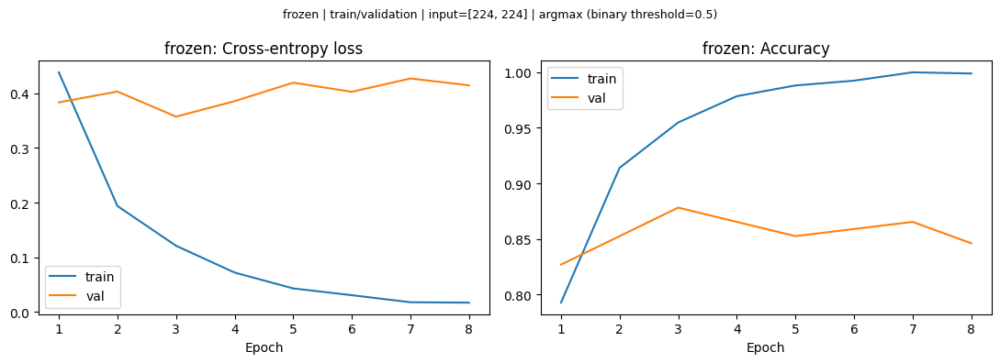

CUMULATIVE TRAINING STAGES — best checkpoints chosen using VALIDATION LOSS only


,stage,split,input_resolution,threshold,best_epoch,epochs_ran,train_accuracy,val_accuracy,val_loss,generalization_gap,val_accuracy_change_pp,val_loss_change,wandb_run_id
0,scratch,validation,"[224, 224]",0.500000,2,7,58.22%,48.08%,0.758481,10.14%,—,—,5srldskp
1,frozen,validation,"[224, 224]",0.500000,3,8,95.49%,87.82%,0.357297,7.67%,39.743590,-0.401184,ag9p0k2n


scratch: /kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/scratch/history.csv | W&B run ID: 5srldskp
frozen: /kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/frozen/history.csv | W&B run ID: ag9p0k2n


,stage,selected_backbone,split,input_resolution,threshold,best_epoch,epochs_ran,train_accuracy,val_accuracy,val_loss,generalization_gap,wandb_run_id,checkpoint,lr_group_0,val_accuracy_change_pp,val_loss_change
0,scratch,Random CNN,validation,"[224, 224]",0.5,2,7,0.582170,0.480769,0.758481,0.101400,5srldskp,/kaggle/working/dfd_indoor_outdoor/outputs/pha...,0.01,NaN,NaN
1,frozen,umm-maybe/AI-image-detector,validation,"[224, 224]",0.5,3,8,0.954887,0.878205,0.357297,0.076682,ag9p0k2n,/kaggle/working/dfd_indoor_outdoor/outputs/pha...,0.01,39.74359,-0.401184


In [47]:
frozen_result=train_experiment('frozen')

report_training_progress(scratch_result,frozen_result)


## 12. Full fine-tuning — all layers trainable


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

full epoch 1:   0%|          | 0/931 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.5239777801104218, 'train_accuracy': 0.7336197636949516, 'val_loss': 0.3901366991414808, 'val_accuracy': 0.8653846153846154, 'lr_group_0': 0.01, 'lr_group_1': 0.001}


full epoch 2:   0%|          | 0/931 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 0.2781283595609488, 'train_accuracy': 0.8872180451127819, 'val_loss': 0.3151000346794414, 'val_accuracy': 0.8974358974358975, 'lr_group_0': 0.01, 'lr_group_1': 0.001}


...

full epoch 14:   0%|          | 0/931 [00:00<?, ?it/s]

{'epoch': 14, 'train_loss': 0.0015621176934493605, 'train_accuracy': 1.0, 'val_loss': 0.11178333351531591, 'val_accuracy': 0.967948717948718, 'lr_group_0': 0.005, 'lr_group_1': 0.0005}


full epoch 15:   0%|          | 0/931 [00:00<?, ?it/s]

{'epoch': 15, 'train_loss': 0.000544743119316753, 'train_accuracy': 1.0, 'val_loss': 0.11727888741978368, 'val_accuracy': 0.9743589743589743, 'lr_group_0': 0.005, 'lr_group_1': 0.0005}


epoch,▁▁▂▃▃▃▄▅▅▅▆▇▇▇█
lr_group_0,█████████████▁▁
lr_group_1,█████████████▁▁
train_accuracy,▁▅▆▇▇▇█████████
train_loss,█▅▄▃▂▂▂▁▁▁▁▁▁▁▁
val_accuracy,▁▃▂▁▄▅▆▄▇▇█████
val_loss,█▆▄▇▄▄▃▅▂▁▁▁▂▁▁
best_val_loss,0.11178
checkpoint,/kaggle/working/dfd_...
epoch,15
lr_group_0,0.005


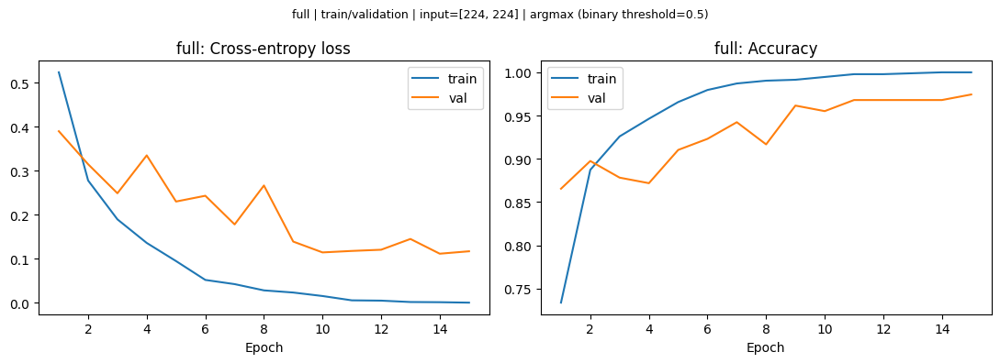

CUMULATIVE TRAINING STAGES — best checkpoints chosen using VALIDATION LOSS only


,stage,split,input_resolution,threshold,best_epoch,epochs_ran,train_accuracy,val_accuracy,val_loss,generalization_gap,val_accuracy_change_pp,val_loss_change,wandb_run_id
0,scratch,validation,"[224, 224]",0.500000,2,7,58.22%,48.08%,0.758481,10.14%,—,—,5srldskp
1,frozen,validation,"[224, 224]",0.500000,3,8,95.49%,87.82%,0.357297,7.67%,39.743590,-0.401184,ag9p0k2n
2,full,validation,"[224, 224]",0.500000,14,15,100.00%,96.79%,0.111783,3.21%,8.974359,-0.245514,dt0yy8ka


scratch: /kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/scratch/history.csv | W&B run ID: 5srldskp
frozen: /kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/frozen/history.csv | W&B run ID: ag9p0k2n
full: /kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/full/history.csv | W&B run ID: dt0yy8ka


,stage,selected_backbone,split,input_resolution,threshold,best_epoch,epochs_ran,train_accuracy,val_accuracy,val_loss,generalization_gap,wandb_run_id,checkpoint,lr_group_0,lr_group_1,val_accuracy_change_pp,val_loss_change
0,scratch,Random CNN,validation,"[224, 224]",0.5,2,7,0.582170,0.480769,0.758481,0.101400,5srldskp,/kaggle/working/dfd_indoor_outdoor/outputs/pha...,0.010,NaN,NaN,NaN
1,frozen,umm-maybe/AI-image-detector,validation,"[224, 224]",0.5,3,8,0.954887,0.878205,0.357297,0.076682,ag9p0k2n,/kaggle/working/dfd_indoor_outdoor/outputs/pha...,0.010,NaN,39.743590,-0.401184
2,full,umm-maybe/AI-image-detector,validation,"[224, 224]",0.5,14,15,1.000000,0.967949,0.111783,0.032051,dt0yy8ka,/kaggle/working/dfd_indoor_outdoor/outputs/pha...,0.005,0.0005,8.974359,-0.245514


In [48]:
full_result=train_experiment('full')

report_training_progress(scratch_result,frozen_result,full_result)


## 13. Lock model selection using VALIDATION only
Select among all three experiments using the same criterion: lowest best-validation cross-entropy.

In [49]:
selection=pd.DataFrame([scratch_result,frozen_result,full_result]).sort_values('best_val_loss')
selection.to_csv(OUT/'validation_selection.csv',index=False)
SELECTED_MODE=str(selection.iloc[0]['mode'])
(OUT/'selection_locked.json').write_text(json.dumps(dict(selected=SELECTED_MODE,criterion='minimum validation cross entropy',timestamp=datetime.now(timezone.utc).isoformat()),indent=2))
display(selection);print('Locked selected model:',SELECTED_MODE)

,mode,checkpoint,best_val_loss,wandb_run_id,input_resolution,threshold,split
2,full,/kaggle/working/dfd_indoor_outdoor/outputs/pha...,0.111783,dt0yy8ka,"[224, 224]",0.5,validation
1,frozen,/kaggle/working/dfd_indoor_outdoor/outputs/pha...,0.357297,ag9p0k2n,"[224, 224]",0.5,validation
0,scratch,/kaggle/working/dfd_indoor_outdoor/outputs/pha...,0.758481,5srldskp,"[224, 224]",0.5,validation


Locked selected model: full


## 14. Evaluation data — exploratory local test or NEW external holdout
Default: evaluate the revised local test and label results exploratory.

In [51]:
TEST_ROOT=ROOT
EVALUATION_STATUS='exploratory: existing data previously used in development'
if CFG['external_manifest']:
    if not CFG['external_root']: raise ValueError('Set external_root for the new holdout.')
    TEST_ROOT=Path(CFG['external_root']).expanduser().resolve()
    test_frame=pd.read_csv(Path(CFG['external_manifest']).expanduser())
    if not {'relative_path','label','scene','group_id'}.issubset(test_frame): raise ValueError('External manifest schema incomplete.')
    external_labels=pd.to_numeric(test_frame.label,errors='raise')
    if not external_labels.isin([0,1]).all(): raise ValueError('Invalid external labels.')
    test_frame['label']=external_labels.astype(int)
    if set(test_frame.label)!={0,1}: raise ValueError('External labels must contain both 0 and 1.')
    if test_frame.relative_path.duplicated().any() or test_frame.group_id.isna().any(): raise ValueError('External duplicate paths/missing groups.')
    old_hashes=set(all_valid.sha256); old_phashes=[int(p,16) for p in all_valid.phash];seen=set()
    if test_frame.group_id.astype(str).str.strip().eq('').any(): raise ValueError('Empty external groups.')
    if set(test_frame.group_id.astype(str)) & set(full_clean.group_id.astype(str)):
        raise ValueError('External group IDs overlap existing groups. Verify global source identity.')
    for row in tqdm(test_frame.itertuples(),total=len(test_frame),desc='Check external overlap'):
        path=(TEST_ROOT/row.relative_path).resolve()
        if not path.is_relative_to(TEST_ROOT.resolve()): raise ValueError('Unsafe external path.')
        digest,ph,w,h=image_fingerprint(path)
        if digest in old_hashes or digest in seen or any((ph^old).bit_count()<=CFG['near_duplicate_distance'] for old in old_phashes):
            raise ValueError(f'External duplicate/near-overlap needs review: {row.relative_path}')
        seen.add(digest)
    test_frame=balanced_frame(test_frame)
    EVALUATION_STATUS='external candidate: automated overlap checks passed; manual provenance verification required'
else: test_frame=clean[clean.split=='test'].copy()
test_frame=test_frame.reset_index(drop=True)
print(EVALUATION_STATUS,'| N =',len(test_frame))

exploratory: existing data previously used in development | N = 164


## 15. M2/M3 metrics — both classes, calibration, uncertainty, slices
Report Accuracy, per-class Precision/Recall/F1, macro-F1, ROC-AUC, confusion matrix, ECE and reliability diagram.

In [52]:
def ece_table(y,p,bins=10):
    pred=(p>=.5).astype(int);confidence=np.maximum(p,1-p)
    index=np.minimum((confidence*bins).astype(int),bins-1)
    rows=[]
    for b in range(bins):
        mask=index==b
        if mask.any(): rows.append(dict(bin=b,n=int(mask.sum()),confidence=float(confidence[mask].mean()),accuracy=float((pred[mask]==y[mask]).mean())))
    table=pd.DataFrame(rows)
    ece=float((table.n/len(y)*(table.accuracy-table.confidence).abs()).sum())
    return ece,table

def accuracy_interval(y,p,groups,iterations=2000):
    frame=pd.DataFrame({'correct':((p>=.5)==y).astype(int),'group':groups})
    agg=frame.groupby('group').correct.agg(['sum','count'])
    if len(agg)<2: return [None,None]
    rng=np.random.default_rng(CFG['seed']);a=agg['sum'].to_numpy();b=agg['count'].to_numpy();values=[]
    for _ in range(iterations):
        indices=rng.integers(0,len(agg),len(agg));values.append(a[indices].sum()/b[indices].sum())
    return np.quantile(values,[.025,.975]).tolist()

def evaluate_experiment(result):
    mode=result['mode'];directory=OUT/mode;kind='cnn' if mode=='scratch' else 'transfer'
    directory.mkdir(exist_ok=True)
    if mode=='pretrained':
        model=AutoModelForImageClassification.from_pretrained(CFG['model_source'],revision=CFG['model_revision'],use_safetensors=None)
        real_index,_=real_class_index(model.config)
    else:
        model=build_model(mode)
        state=torch.load(result['checkpoint'],map_location='cpu',weights_only=True)
        model.load_state_dict(state['state_dict'])
    model=model.to(DEVICE).eval()
    loader=make_loader(test_frame,kind,root=TEST_ROOT);scores=[];labels=[];input_shape=None
    with torch.inference_mode():
        for x,y in tqdm(loader,desc='Evaluate '+mode):
            input_shape=list(x.shape[-2:])
            probabilities=torch.softmax(logits_for(model,x.to(DEVICE),mode),dim=1)
            p=1-probabilities[:,real_index] if mode=='pretrained' else probabilities[:,1]
            scores.extend(p.cpu().tolist());labels.extend(y.tolist())
    del model;gc.collect();clear_device_cache()
    p=np.asarray(scores);y=np.asarray(labels);pred=(p>=.5).astype(int)
    assert np.array_equal(y,test_frame.label.to_numpy())
    if not np.isfinite(p).all() or ((p<0)|(p>1)).any(): raise ValueError('Invalid probabilities.')
    precision,recall,f1,support=precision_recall_fscore_support(y,pred,labels=[0,1],zero_division=0)
    per_class=pd.DataFrame({'class':['Real','Fake'],'precision':precision,'recall':recall,'f1':f1,'support':support})
    per_class.to_csv(directory/'per_class_metrics.csv',index=False)
    ece,reliability=ece_table(y,p)
    interval=accuracy_interval(y,p,test_frame.group_id)
    summary=dict(mode=mode,accuracy=float(accuracy_score(y,pred)),top1_accuracy=float(accuracy_score(y,pred)),
                 top2_accuracy=1.0,macro_f1=float(f1.mean()),roc_auc=float(roc_auc_score(y,p)),ece=ece,
                 accuracy_ci95_low=interval[0],accuracy_ci95_high=interval[1],n_test=len(y),
                 split='external_candidate' if CFG['external_manifest'] else 'exploratory_test',
                 input_resolution=str(input_shape),threshold=.5,evaluation_status=EVALUATION_STATUS)
    for i,label in enumerate(['real','fake']):
        summary.update({f'{label}_precision':float(precision[i]),f'{label}_recall':float(recall[i]),f'{label}_f1':float(f1[i])})
    predictions=test_frame.copy();predictions['prob_fake']=p;predictions['prediction']=pred
    predictions['evaluation_split']='external' if CFG['external_manifest'] else 'exploratory_test'
    predictions['input_resolution']=str(input_shape);predictions['threshold']=.5
    predictions.to_csv(directory/'test_predictions.csv',index=False)
    (directory/'metrics.json').write_text(json.dumps(summary,indent=2))
    slices=[]
    for scene,part in predictions.groupby('scene'):
        slices.append({'scene':scene,'n':len(part),'accuracy':accuracy_score(part.label,part.prediction)})
    pd.DataFrame(slices).to_csv(directory/'scene_metrics.csv',index=False)
    fig,axes=plt.subplots(1,2,figsize=(11,4))
    ConfusionMatrixDisplay(confusion_matrix(y,pred,labels=[0,1]),display_labels=['Real','Fake']).plot(ax=axes[0],colorbar=False)
    axes[1].plot([0,1],[0,1],'--',color='gray');axes[1].plot(reliability.confidence,reliability.accuracy,'o-')
    axes[1].set(xlabel='Mean confidence',ylabel='Empirical accuracy',title=f'ECE={ece:.4f}',xlim=(0,1),ylim=(0,1))
    fig.suptitle(f'{mode} | {EVALUATION_STATUS} | input={input_shape} | threshold=0.5',fontsize=8)
    plt.tight_layout();plt.savefig(directory/'confusion_and_calibration.png',dpi=170);plt.show()
    reliability.to_csv(directory/'reliability_bins.csv',index=False)
    run=wandb.init(project=CFG['wandb_project'],name=mode+'_evaluation_'+RUN_ID,group=RUN_ID,
        config={**CFG,'experiment':mode},mode=CFG['wandb_mode'],dir=str(OUT),reinit='finish_previous')
    run.log(summary);run.log({'per_class':wandb.Table(dataframe=per_class)})
    run.finish();display(per_class)
    return summary

Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

Evaluate pretrained:   0%|          | 0/164 [00:00<?, ?it/s]

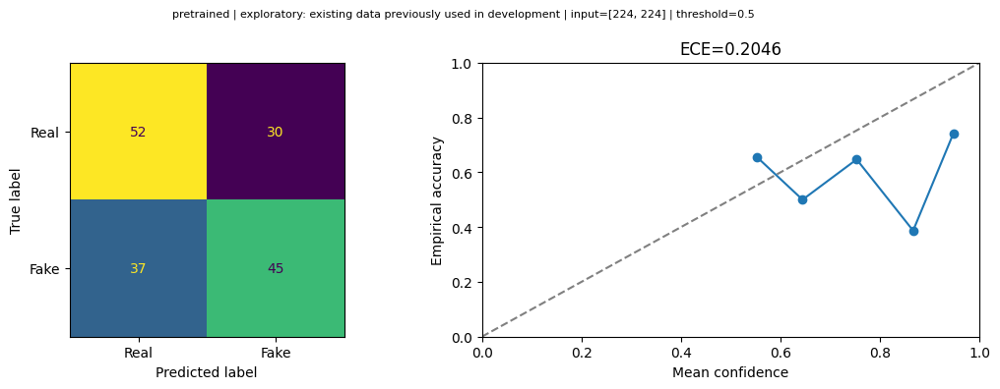

accuracy,▁
accuracy_ci95_high,▁
accuracy_ci95_low,▁
ece,▁
fake_f1,▁
fake_precision,▁
fake_recall,▁
macro_f1,▁
n_test,▁
real_f1,▁
+6,...


,class,precision,recall,f1,support
0,Real,0.58427,0.634146,0.608187,82
1,Fake,0.60000,0.548780,0.573248,82


Evaluate scratch:   0%|          | 0/164 [00:00<?, ?it/s]

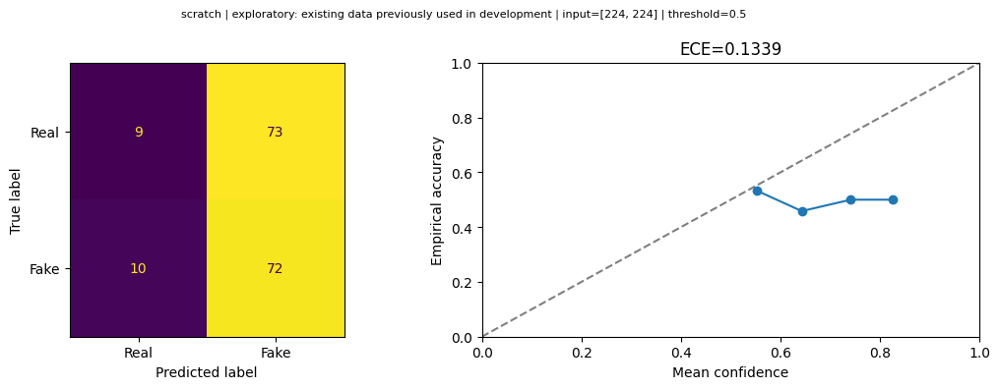

accuracy,▁
accuracy_ci95_high,▁
accuracy_ci95_low,▁
ece,▁
fake_f1,▁
fake_precision,▁
fake_recall,▁
macro_f1,▁
n_test,▁
real_f1,▁
+6,...


,class,precision,recall,f1,support
0,Real,0.473684,0.109756,0.178218,82
1,Fake,0.496552,0.878049,0.634361,82


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

Evaluate frozen:   0%|          | 0/164 [00:00<?, ?it/s]

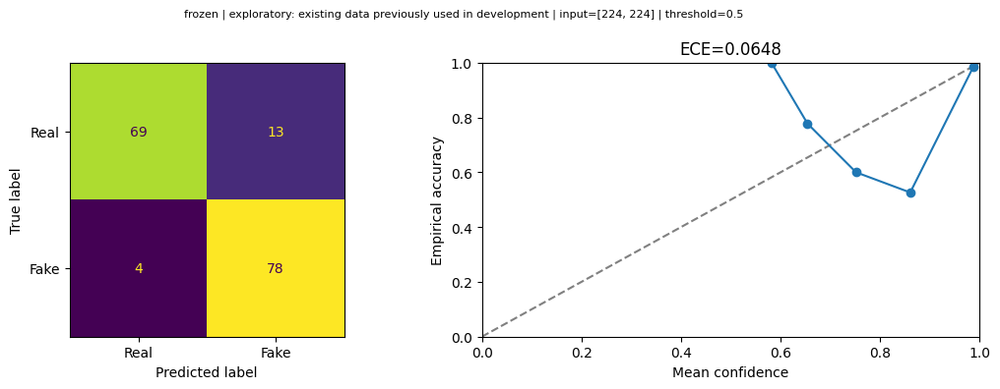

accuracy,▁
accuracy_ci95_high,▁
accuracy_ci95_low,▁
ece,▁
fake_f1,▁
fake_precision,▁
fake_recall,▁
macro_f1,▁
n_test,▁
real_f1,▁
+6,...


,class,precision,recall,f1,support
0,Real,0.945205,0.841463,0.890323,82
1,Fake,0.857143,0.951220,0.901734,82


Loading weights:   0%|          | 0/425 [00:00<?, ?it/s]

Evaluate full:   0%|          | 0/164 [00:00<?, ?it/s]

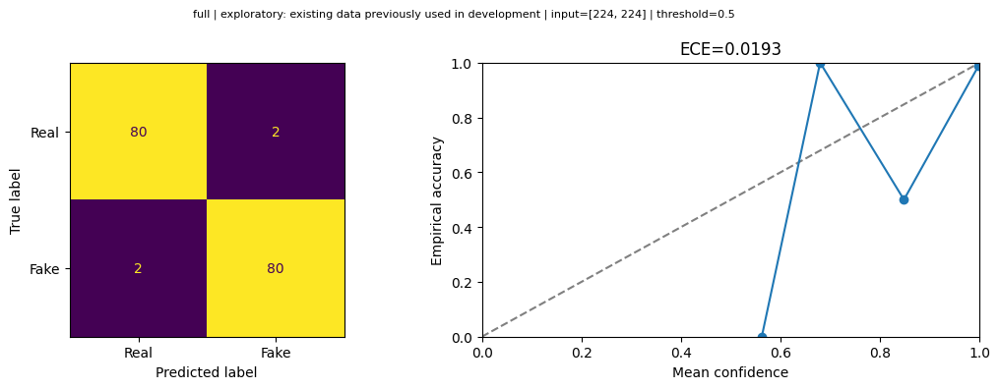

accuracy,▁
accuracy_ci95_high,▁
accuracy_ci95_low,▁
ece,▁
fake_f1,▁
fake_precision,▁
fake_recall,▁
macro_f1,▁
n_test,▁
real_f1,▁
+6,...


,class,precision,recall,f1,support
0,Real,0.97561,0.97561,0.97561,82
1,Fake,0.97561,0.97561,0.97561,82


,mode,accuracy,top1_accuracy,top2_accuracy,macro_f1,roc_auc,ece,accuracy_ci95_low,accuracy_ci95_high,n_test,...,input_resolution,threshold,evaluation_status,real_precision,real_recall,real_f1,fake_precision,fake_recall,fake_f1,selected_by_validation
0,pretrained,0.591463,0.591463,1.0,0.590718,0.602617,0.204639,0.512195,0.664634,164,...,"[224, 224]",0.5,exploratory: existing data previously used in ...,0.584270,0.634146,0.608187,0.600000,0.548780,0.573248,False
1,scratch,0.493902,0.493902,1.0,0.406290,0.449732,0.133905,0.420732,0.573171,164,...,"[224, 224]",0.5,exploratory: existing data previously used in ...,0.473684,0.109756,0.178218,0.496552,0.878049,0.634361,False
2,frozen,0.896341,0.896341,1.0,0.896028,0.962820,0.064801,0.847561,0.939024,164,...,"[224, 224]",0.5,exploratory: existing data previously used in ...,0.945205,0.841463,0.890323,0.857143,0.951220,0.901734,False
3,full,0.975610,0.975610,1.0,0.975610,0.997620,0.019297,0.951220,0.993902,164,...,"[224, 224]",0.5,exploratory: existing data previously used in ...,0.975610,0.975610,0.975610,0.975610,0.975610,0.975610,True


Keep the validation-selected choice: full — do not reselect using test results.


In [53]:
test_results=[evaluate_experiment(r) for r in [dict(mode='pretrained'),scratch_result,frozen_result,full_result]]
comparison=pd.DataFrame(test_results)
comparison['selected_by_validation']=comparison['mode'].eq(SELECTED_MODE)
comparison.to_csv(OUT/'final_comparison.csv',index=False)
display(comparison)
print('Keep the validation-selected choice:',SELECTED_MODE,'— do not reselect using test results.')

### Final comparison report — all inference baselines and all trained stages

This produces two separate tables: **(A)** five original pretrained checkpoints evaluated on validation and **(B)** scratch, frozen, and full fine-tuning evaluated on the same chosen test split. 

A — FIVE PRETRAINED MODELS: VALIDATION (inference only)


,model,architecture,split,input_resolution,threshold,n,accuracy,macro_f1,fake_f1,roc_auc,accuracy_indoor,accuracy_outdoor
0,Swin_AI_Image,swin,validation,"[224, 224]",0.500000,156,56.41%,56.38%,55.26%,0.587607,51.72%,62.32%
1,SigLIP2_Deepfake,siglip,validation,"[224, 224]",0.500000,156,44.23%,44.21%,45.28%,0.374260,37.93%,52.17%
2,ViT_Dima,vit,validation,"[224, 224]",0.500000,156,45.51%,41.03%,57.29%,0.438527,43.68%,47.83%
3,SigLIP2_ThreeClass,siglip,validation,"[224, 224]",0.500000,156,39.74%,37.74%,48.91%,0.320842,43.68%,34.78%
4,ViT_ThreeClass,vit,validation,"[224, 224]",0.500000,156,50.64%,35.80%,66.67%,0.448882,52.87%,47.83%


B — SCRATCH → FROZEN → FULL: SAME TEST SPLIT, selected by VALIDATION


,mode,split,input_resolution,threshold,n_test,accuracy,macro_f1,real_f1,fake_f1,roc_auc,ece,selected_by_validation,accuracy_change_pp,macro_f1_change_pp
0,pretrained,exploratory_test,"[224, 224]",0.500000,164,59.15%,59.07%,60.82%,57.32%,0.602617,20.46%,False,—,—
1,scratch,exploratory_test,"[224, 224]",0.500000,164,49.39%,40.63%,17.82%,63.44%,0.449732,13.39%,False,-9.756098,-18.442824
2,frozen,exploratory_test,"[224, 224]",0.500000,164,89.63%,89.60%,89.03%,90.17%,0.962820,6.48%,False,40.243902,48.973881
3,full,exploratory_test,"[224, 224]",0.500000,164,97.56%,97.56%,97.56%,97.56%,0.997620,1.93%,True,7.926829,7.958141


C — EPOCH-BY-EPOCH TRAINING AND VALIDATION LOGS (NOT TEST)
CUMULATIVE TRAINING STAGES — best checkpoints chosen using VALIDATION LOSS only


,stage,split,input_resolution,threshold,best_epoch,epochs_ran,train_accuracy,val_accuracy,val_loss,generalization_gap,val_accuracy_change_pp,val_loss_change,wandb_run_id
0,scratch,validation,"[224, 224]",0.500000,2,7,58.22%,48.08%,0.758481,10.14%,—,—,5srldskp
1,frozen,validation,"[224, 224]",0.500000,3,8,95.49%,87.82%,0.357297,7.67%,39.743590,-0.401184,ag9p0k2n
2,full,validation,"[224, 224]",0.500000,14,15,100.00%,96.79%,0.111783,3.21%,8.974359,-0.245514,dt0yy8ka


scratch: /kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/scratch/history.csv | W&B run ID: 5srldskp
frozen: /kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/frozen/history.csv | W&B run ID: ag9p0k2n
full: /kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/full/history.csv | W&B run ID: dt0yy8ka


,epoch,train_loss,train_accuracy,val_loss,val_accuracy,lr_group_0,stage,lr_group_1
18,4,0.136255,0.946294,0.335220,0.871795,0.010,full,0.0010
19,5,0.095030,0.965628,0.230339,0.910256,0.010,full,0.0010
20,6,0.052164,0.979592,0.243457,0.923077,0.010,full,0.0010
21,7,0.042641,0.987111,0.178325,0.942308,0.010,full,0.0010
22,8,0.028440,0.990333,0.266777,0.916667,0.010,full,0.0010
23,9,0.023539,0.991407,0.139312,0.961538,0.010,full,0.0010
24,10,0.015600,0.994629,0.114692,0.955128,0.010,full,0.0010
25,11,0.005782,0.997852,0.118072,0.967949,0.010,full,0.0010
26,12,0.005117,0.997852,0.120795,0.967949,0.010,full,0.0010
27,13,0.001974,0.998926,0.145270,0.967949,0.010,full,0.0010


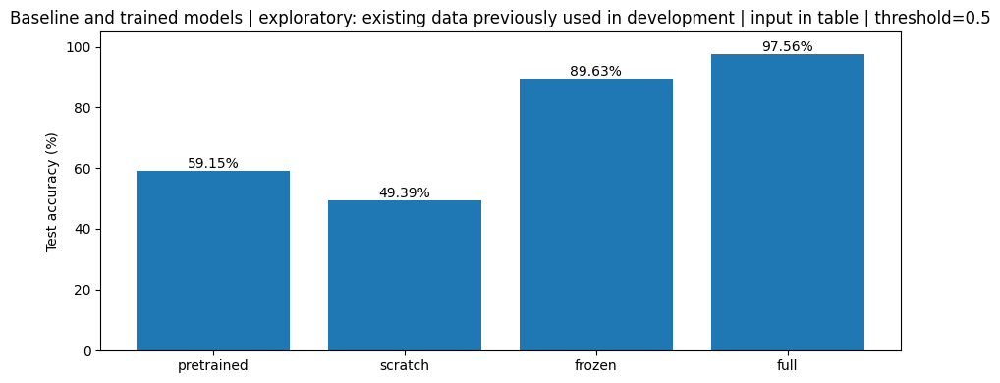

Reports saved under: /kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z


In [54]:
#Final reporting only
print('A — FIVE PRETRAINED MODELS: VALIDATION (inference only)')
pre_cols=['model','architecture','split','input_resolution','threshold','n','accuracy','macro_f1','fake_f1','roc_auc','accuracy_indoor','accuracy_outdoor']
pre_table=pretrained_comparison[[c for c in pre_cols if c in pretrained_comparison.columns]].copy()
pre_table.to_csv(OUT/'report_pretrained_validation.csv',index=False)
display(pre_table.style.format({c:'{:.2%}' for c in ['accuracy','macro_f1','fake_f1','accuracy_indoor','accuracy_outdoor'] if c in pre_table.columns},na_rep='—'))

print('B — SCRATCH → FROZEN → FULL: SAME TEST SPLIT, selected by VALIDATION')
stage_order=['pretrained','scratch','frozen','full']
final_table=comparison.set_index('mode').loc[stage_order].reset_index()
show_cols=['mode','split','input_resolution','threshold','n_test','accuracy','macro_f1','real_f1','fake_f1','roc_auc','ece','selected_by_validation']
final_table=final_table[[c for c in show_cols if c in final_table.columns]].copy()
final_table['accuracy_change_pp']=final_table.accuracy.diff()*100
final_table['macro_f1_change_pp']=final_table.macro_f1.diff()*100
final_table.to_csv(OUT/'report_training_test_comparison.csv',index=False)
display(final_table.style.format({c:'{:.2%}' for c in ['accuracy','macro_f1','real_f1','fake_f1','ece'] if c in final_table.columns},na_rep='—'))

print('C — EPOCH-BY-EPOCH TRAINING AND VALIDATION LOGS (NOT TEST)')
progress=report_training_progress(scratch_result,frozen_result,full_result)
epoch_logs=pd.concat([pd.read_csv(OUT/m/'history.csv').assign(stage=m) for m in ['scratch','frozen','full']],ignore_index=True)
epoch_logs.to_csv(OUT/'report_all_epoch_logs.csv',index=False)
display(epoch_logs.tail(12))

fig,ax=plt.subplots(figsize=(9,4))
ax.bar(final_table['mode'],final_table['accuracy']*100,label='Test accuracy')
for i,r in final_table.iterrows(): ax.annotate(f"{r['accuracy']:.2%}",(i,r['accuracy']*100),ha='center',va='bottom')
ax.set(ylabel='Test accuracy (%)',ylim=(0,105),title=f'Baseline and trained models | {EVALUATION_STATUS} | input in table | threshold=0.5')
plt.tight_layout();plt.savefig(OUT/'report_baseline_and_trained_test_accuracy.png',dpi=170);plt.show()
print('Reports saved under:',OUT)

## 16. Error galleries and a data-improvement plan
Inspect errors for **each** trained model, not only the winner.

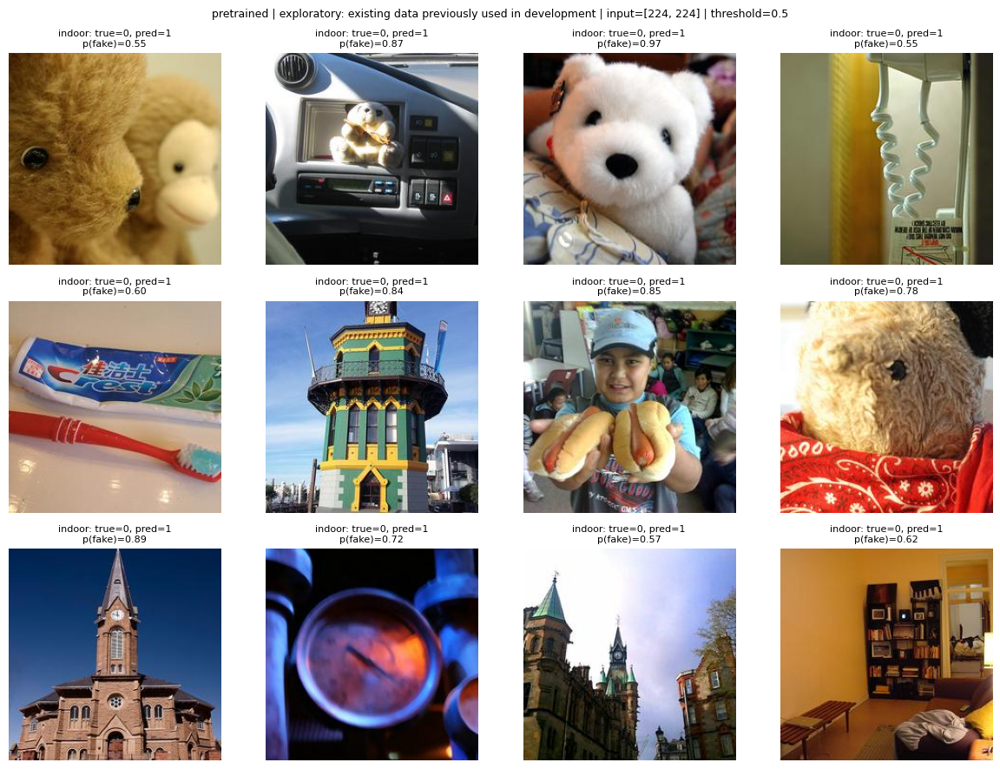

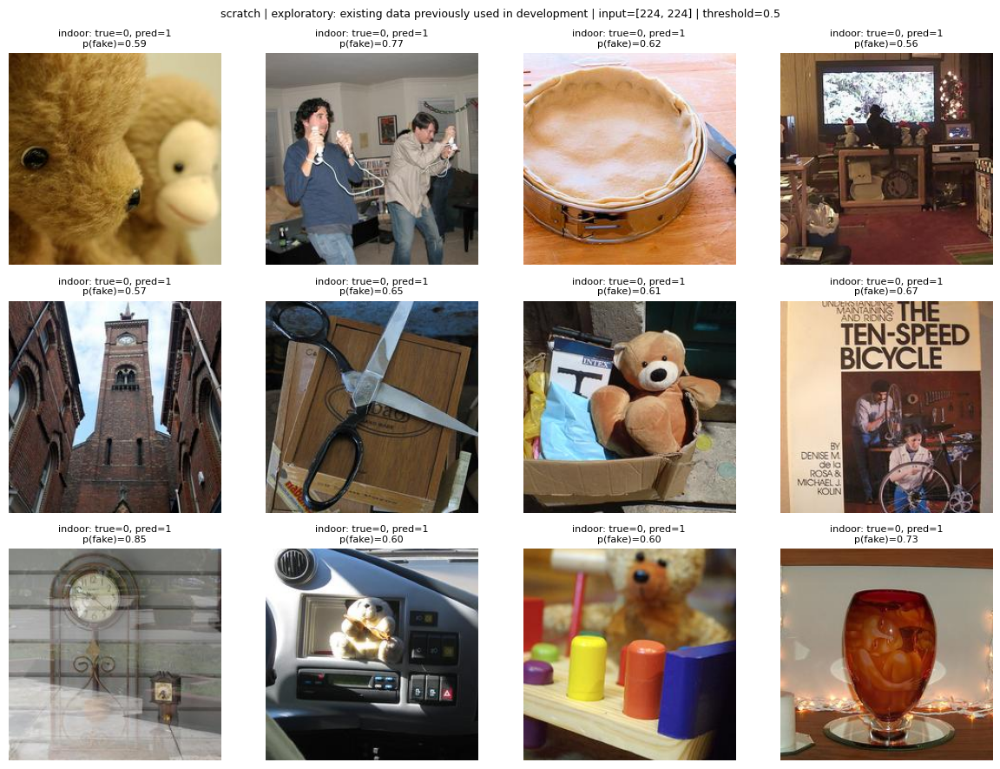

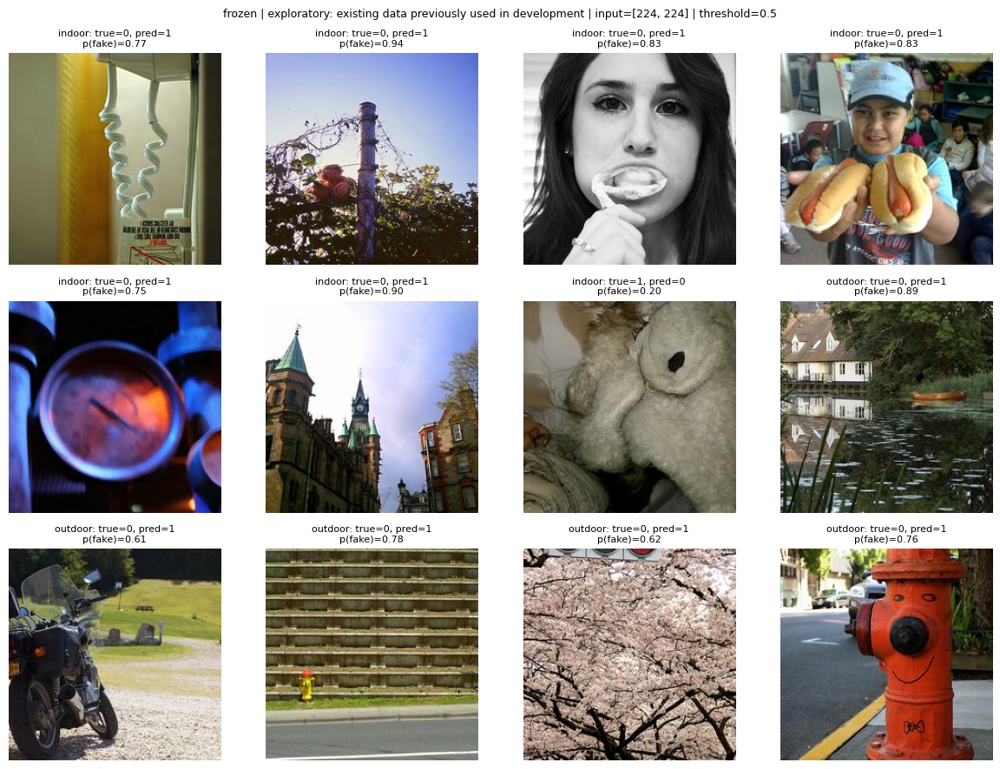

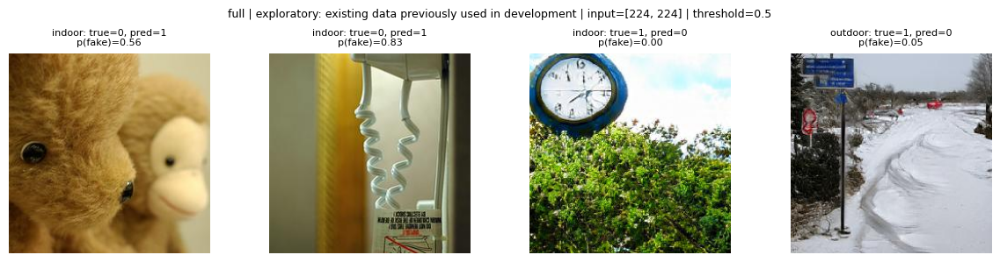

Complete error_review.csv for each model and data_improvement_plan.md.


In [55]:
for mode in ['pretrained','scratch','frozen','full']:
    directory=OUT/mode;predictions=pd.read_csv(directory/'test_predictions.csv')
    wrong=predictions[predictions.label!=predictions.prediction].copy()
    wrong['error_type']=np.where(wrong.label.eq(1),'False negative: fake predicted real','False positive: real predicted fake')
    wrong['failure_cause']='';wrong['evidence']='';wrong['data_improvement_action']=''
    if not (directory/'error_review.csv').exists():
        wrong.to_csv(directory/'error_review.csv',index=False)
    sample=wrong.head(12)
    if not sample.empty:
        fig,axes=plt.subplots(int(np.ceil(len(sample)/4)),4,figsize=(12,3*int(np.ceil(len(sample)/4))),squeeze=False)
        for ax in axes.flat: ax.axis('off')
        for ax,(_,row) in zip(axes.flat,sample.iterrows()):
            with Image.open(TEST_ROOT/row.relative_path) as im: ax.imshow(ImageOps.exif_transpose(im).convert('RGB'))
            ax.set_title(f'{row.scene}: true={row.label}, pred={row.prediction}\np(fake)={row.prob_fake:.2f}',fontsize=8)
        fig.suptitle(f'{mode} | {EVALUATION_STATUS} | input={predictions.input_resolution.iloc[0]} | threshold=0.5',fontsize=9);plt.tight_layout()
        plt.savefig(directory/'error_gallery.png',dpi=160);plt.show()
if not (OUT/'data_improvement_plan.md').exists():
    (OUT/'data_improvement_plan.md').write_text('# Data-improvement plan — complete after error review\nFor each model, summarize the false positives and false negatives in error_review.csv.\n1. Observed failure pattern and number of supporting examples: TODO\n2. Evidence (image IDs, source/scene/generator slices): TODO\n3. Proposed data action (labels, diversity, resolution, sources): TODO\n4. Validation experiment and acceptance metric: TODO\n5. Limitations and evaluation set affected by this analysis: TODO\nDo not infer image authenticity from appearance alone. Do not claim a cause without evidence.\n')
print('Complete error_review.csv for each model and data_improvement_plan.md.')

In [ ]:
validation_summaries = []
for name in PRETRAINED_SOURCES:
    frame = pd.read_csv(BASELINE_DIR / (name + "_validation_predictions.csv"))
    y = frame.label.to_numpy(); p = frame.prob_fake.to_numpy()
    ece, table = ece_table(y, p, bins=CFG["ece_bins"])
    table.to_csv(BASELINE_DIR / (name + "_reliability.csv"), index=False)
    row = pretrained_comparison.loc[pretrained_comparison.model.eq(name)].iloc[0].to_dict()
    row.update(top1_accuracy=row["accuracy"], top2_accuracy=1.0, ece=ece)
    validation_summaries.append(row)
    run = wandb.init(project=CFG["wandb_project"], name=name+"_validation_calibration_"+RUN_ID,
                     group=RUN_ID, config=CFG, mode=CFG["wandb_mode"], dir=str(OUT),
                     reinit="finish_previous")
    try:
        run.log(row)
    finally:
        run.finish()
pd.DataFrame(validation_summaries).to_csv(OUT / "pretrained_validation_complete_metrics.csv", index=False)

accuracy,▁
accuracy_indoor,▁
accuracy_outdoor,▁
binary_log_loss,▁
ece,▁
fake_f1,▁
fake_precision,▁
fake_recall,▁
macro_f1,▁
n,▁
+7,...


accuracy,▁
accuracy_indoor,▁
accuracy_outdoor,▁
binary_log_loss,▁
ece,▁
fake_f1,▁
fake_precision,▁
fake_recall,▁
macro_f1,▁
n,▁
+7,...


accuracy,▁
accuracy_indoor,▁
accuracy_outdoor,▁
binary_log_loss,▁
ece,▁
fake_f1,▁
fake_precision,▁
fake_recall,▁
macro_f1,▁
n,▁
+7,...


accuracy,▁
accuracy_indoor,▁
accuracy_outdoor,▁
binary_log_loss,▁
ece,▁
fake_f1,▁
fake_precision,▁
fake_recall,▁
macro_f1,▁
n,▁
+7,...


accuracy,▁
accuracy_indoor,▁
accuracy_outdoor,▁
binary_log_loss,▁
ece,▁
fake_f1,▁
fake_precision,▁
fake_recall,▁
macro_f1,▁
n,▁
+7,...


## 17. Submission checklist and repository package


In [61]:
readme=f"""# Phase 1: Kaggle Real/Fake classification
Run the notebook in order on Kaggle with GPU and Internet enabled.
Images are read from the attached private Kaggle Dataset under /kaggle/input/.
No dataset image streaming is performed. Output files are saved under /kaggle/working/.
Install requirements-lock.txt in a separate compatible Python environment.
Modes: scratch CNN, frozen backbone/head training, full fine-tuning.
Optimizer: SGD with L2 weight decay; validation scheduler and early stopping.
Selection: minimum validation loss. Selected mode: {SELECTED_MODE}.
Evaluation status: {EVALUATION_STATUS}.
Exact bitwise CUDA reproducibility is not guaranteed across hardware/software versions.
Report labels 0=Real, 1=Fake; top-2 is trivial for binary classification.
Review phase1_review files; finish error analysis and dataset card before submission.
Do not commit images, model cache, W&B credentials, or large checkpoints.
W&B: offline runs must be synced before sharing the project comparison link.
"""
(OUT/'README.md').write_text(readme)
(OUT/'.gitignore').write_text('data/\n*.pt\n*.safetensors\n*.png\n*.jpg\n*.jpeg\n*.webp\n*.zip\nwandb/\n.env\n.ipynb_checkpoints/\n')
checklist=pd.DataFrame([
    ('Local cleaning and duplicate report','generated'),('Group provenance verification','complete' if GROUP_REVIEW_COMPLETE else 'MANUAL REVIEW REQUIRED'),
    ('Label audit with confidence bound','complete' if AUDIT_COMPLETE else 'MANUAL REVIEW REQUIRED'),
    ('Dataset card','complete' if CARD_COMPLETE else 'MANUAL DOCUMENTATION REQUIRED'),
    ('Five pretrained validation inference baselines','see pretrained_validation_complete_metrics.csv'),('Scratch, frozen and full training','see training_result.json for each run'),('Schedulers, L2, early stopping','included in all three'),
    ('Per-class metrics, ECE, accuracy CI','generated'),('Independent final holdout',EVALUATION_STATUS),
    ('Error explanations and improvement plan','MANUAL ANALYSIS REQUIRED'),
    ('W&B comparison link','SYNC REQUIRED' if CFG['wandb_mode']=='offline' else 'check online project'),
    ('Clean repository and teammate reproduction','COMPLETE OUTSIDE NOTEBOOK'),
],columns=['requirement','status'])
checklist.to_csv(OUT/'submission_checklist.csv',index=False);display(checklist)
for path in sorted((OUT/'wandb').glob('offline-run-*')): print('wandb sync',repr(str(path)))
print('Phase One is NOT certified complete: inspect all evidence and resolve manual items.')
print('Phase Two is not implemented; explicit approval is required.')
print('All new files:',OUT)
print('No original images, original manifest, or earlier experiment outputs were overwritten.')

,requirement,status
0,Local cleaning and duplicate report,generated
1,Group provenance verification,MANUAL REVIEW REQUIRED
2,Label audit with confidence bound,MANUAL REVIEW REQUIRED
3,Dataset card,complete
4,Five pretrained validation inference baselines,see pretrained_validation_complete_metrics.csv
5,"Scratch, frozen and full training",see training_result.json for each run
6,"Schedulers, L2, early stopping",included in all three
7,"Per-class metrics, ECE, accuracy CI",generated
8,Independent final holdout,exploratory: existing data previously used in ...
9,Error explanations and improvement plan,MANUAL ANALYSIS REQUIRED


wandb sync '/kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/wandb/offline-run-20261028_234940-ibbxwmr3'
wandb sync '/kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/wandb/offline-run-20261028_235000-a83ffpgs'
wandb sync '/kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/wandb/offline-run-20261028_235023-qab94c3r'
wandb sync '/kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/wandb/offline-run-20261028_235042-w4yqichb'
wandb sync '/kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/wandb/offline-run-20261028_235113-iocmjbcr'
wandb sync '/kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/wandb/offline-run-20261028_235308-5srldskp'
wandb sync '/kaggle/working/dfd_indoor_outdoor/outputs/phase1_kaggle_20261028T234549315015Z/wandb/offline-run-20261028_235452-ag9p0k2n'
wandb sync '/kaggle/working/dfd_indoor_outdoor/o

In [64]:
import wandb

image_path = "/kaggle/input/datasets/anoudmohammd/data-conf-matrix-result/full_confusion_and_calibration.png"

run = wandb.init(
    entity="ifbf-kaust",
    project="DFD IMAGES IN SAUDI ARABIA",
    name="full_evaluation_images",
    mode="online")

run.log({
    "full/confusion_and_calibration": wandb.Image(
        image_path,
        caption="Full Fine-Tuning | Exploratory Evaluation | 164 images | 224x224 | threshold=0.5")})

run.finish()
print("Image uploaded successfully!")

Image uploaded successfully!
